Loading data...
  fronts: 269, surf: 900, conv: 500
  Layout parameters:
    a: [0.050, 0.420, 0.500, 0.560]
    b: [0.590, 0.722, 0.360, 0.258]
    c: [0.590, 0.420, 0.360, 0.258]
    d/e/f width = 0.233


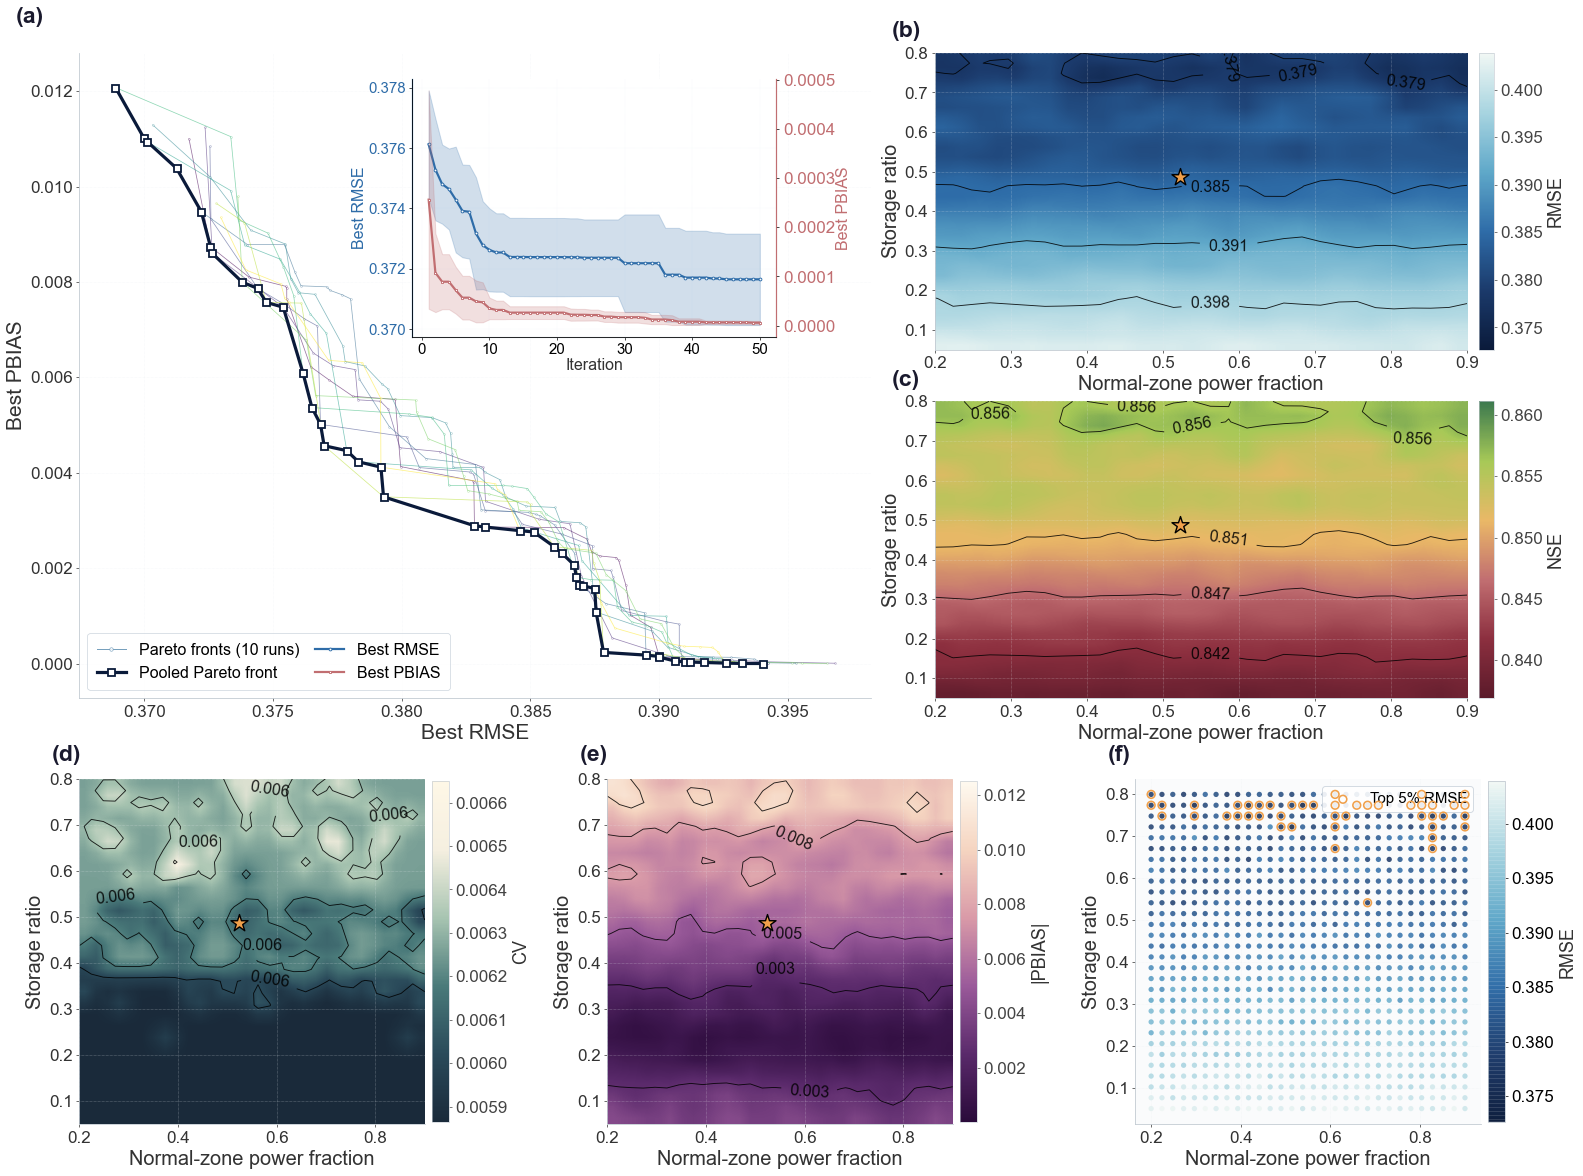

Saved: D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular\Figure_A_enCalibration_and_Parameter_Identifiability.png


In [2]:
# -*- coding: utf-8 -*-
"""
Figure A: Calibration results and parameter identifiability
    (a) Main panel: Pareto fronts from 10 runs + pooled front
        + inset convergence curves
    (b) RMSE_norm response surface + TOPSIS star + contour lines
    (c) NSE response surface + TOPSIS star + contour lines
    (d) CV response surface + TOPSIS star + contour lines
    (e) |PBIAS|_norm response surface + TOPSIS star + contour lines
    (f) Joint parameter-objective scatter
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter


# ============================================================
# ========== Global font-size settings (edit here) ===========
# ============================================================
FS_LABEL       = 20
FS_TICK        = 17
FS_LEGEND      = 16
FS_PANEL       = 23
FS_CB_LABEL    = 18
FS_CB_TICK     = 16
FS_ANNO        = 16
FS_INSET_LABEL = 16
FS_INSET_TICK  = 15
FS_INSET_TITLE = 16

rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False
rcParams['font.size'] = FS_LABEL
rcParams['axes.linewidth'] = 0.8
rcParams['xtick.major.width'] = 0.7
rcParams['ytick.major.width'] = 0.7
rcParams['xtick.major.size'] = 3
rcParams['ytick.major.size'] = 3


# ============================================================
# ========== Layout parameters (edit here) ===================
# ============================================================
LAYOUT = {
    # Overall margins
    'margin_left':   0.050,
    'margin_right':  0.050,
    'margin_bottom': 0.050,
    'margin_top':    0.050,

    # Internal gaps of the top region
    'h_gap_top':     0.040,   # horizontal gap between a and b/c
    'v_gap_top':     0.045,   # vertical gap between b and c

    # Horizontal gap between the three bottom panels
    'h_gap_bot':     0.1,

    # Vertical gap between the top and bottom regions
    'v_gap_mid':     0.070,

    # Size of each region
    'a_width':       0.500,   # width of panel (a)
    'top_height':    0.560,   # height of the top region (a and b+c)
    'bot_height':    0.30,    # height of the bottom panels
}


# ========== Paths ==========
DATA_PATH = r"D:\Python code\boshilunwen\电站模拟\results_kaidu_20261012_140128"
OUTPUT_PATH = r"D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular"
os.makedirs(OUTPUT_PATH, exist_ok=True)

UD = os.path.join(DATA_PATH, 'uncertainty')
SURF_DIR = os.path.join(UD, 'param_surface')
P_FRONT = os.path.join(DATA_PATH, 'mopso_pareto_front.csv')

P1 = 'normal_zone_power_fraction'
P2 = 'storage_ratio'
P1_EN = 'Normal-zone power fraction'
P2_EN = 'Storage ratio'


# ========== Colormaps ==========
CMAP_RMSE = LinearSegmentedColormap.from_list(
    'modern_rmse', ['#0a1a3a', '#1b3a6b', '#2e6ca8',
                    '#5fa8c9', '#a7d4e0', '#f0f7f4'], N=256)
CMAP_NSE = LinearSegmentedColormap.from_list(
    'modern_nse', ['#5a1a2a', '#8c2f3f', '#c16e71',
                   '#eab867', '#a7c957', '#3d7a4f'], N=256)
CMAP_CV = LinearSegmentedColormap.from_list(
    'modern_cv', ['#1a2a3a', '#2a4a5a', '#4a7a7a',
                  '#a7c4b1', '#f5efe0', '#fef7e6'], N=256)
CMAP_PBIAS = LinearSegmentedColormap.from_list(
    'modern_pbias', ['#2a0a3a', '#5a2a6b', '#9a5a9a',
                     '#d99aa8', '#f5d4c0', '#fef9ef'], N=256)

COL_P1 = '#2e6ca8'
COL_P2 = '#c16e71'
COL_HL = '#f0a04b'
COL_POOL = '#0a1a3a'
COL_BG = '#fafbfc'
COL_GRID = '#e8ecf0'


# ========== Utility functions ==========
def add_panel_label(ax, label):
    """Panel label: no frame, no background."""
    ax.text(-0.08, 1.04, label, transform=ax.transAxes,
            fontsize=FS_PANEL, fontweight='bold',
            va='bottom', ha='left', clip_on=False,
            color='#1a1a2e')


def style_axis(ax, add_bg=True):
    ax.grid(True, linestyle=':', linewidth=0.5,
            color=COL_GRID, alpha=0.7, zorder=0)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_color('#c0c8d0')
        ax.spines[spine].set_linewidth(0.8)
    ax.tick_params(axis='both', labelsize=FS_TICK,
                   colors='#333333')
    if add_bg:
        ax.set_facecolor(COL_BG)
    else:
        ax.set_facecolor('white')


def pivot_2d(df, val):
    return df.pivot_table(index=P2, columns=P1,
                          values=val, aggfunc='mean')


def smooth_surface(Z, sigma=0.8):
    if np.any(np.isnan(Z)):
        Z_filled = np.where(np.isnan(Z), np.nanmean(Z), Z)
    else:
        Z_filled = Z
    return gaussian_filter(Z_filled, sigma=sigma)


def get_topsis_best():
    if not os.path.exists(P_FRONT):
        return None
    pf = pd.read_csv(P_FRONT)
    if P1 not in pf.columns or P2 not in pf.columns:
        return None
    F = pf[['Objective_RMSE_norm', 'Objective_PBIAS_norm']].values
    fmin, fmax = F.min(axis=0), F.max(axis=0)
    den = np.where(fmax - fmin > 1e-12, fmax - fmin, 1.0)
    Z = (F - fmin) / den
    dp = np.linalg.norm(Z - 0, axis=1)
    dn = np.linalg.norm(Z - 1, axis=1)
    sc = dn / (dp + dn + 1e-12)
    bi = int(np.argmax(sc))
    return pf[P1].values[bi], pf[P2].values[bi]


def add_topsis_star(ax):
    """Overlay the TOPSIS-optimal star on b-e (not on a)."""
    best = get_topsis_best()
    if best is None:
        return
    bx, by = best
    ax.scatter(bx, by, s=320, marker='*',
               color=COL_HL,
               edgecolor='black', linewidth=1.4,
               zorder=20)


def heatmap(ax, pivot, cmap, panel, cb_label,
            add_contour=False):
    X = pivot.columns.values
    Y = pivot.index.values
    Z = pivot.values
    Z_plot = smooth_surface(Z, sigma=0.8)

    im = ax.imshow(Z_plot, cmap=cmap,
                   extent=[X.min(), X.max(),
                           Y.min(), Y.max()],
                   origin='lower', aspect='auto',
                   interpolation='bilinear',
                   vmin=np.nanmin(Z), vmax=np.nanmax(Z))

    cb = plt.colorbar(im, ax=ax, pad=0.02, fraction=0.046)
    cb.set_label(cb_label, fontsize=FS_CB_LABEL,
                 color='#333333')
    cb.ax.tick_params(labelsize=FS_CB_TICK, colors='#444444')
    cb.outline.set_edgecolor('#c0c8d0')
    cb.outline.set_linewidth(0.6)

    if add_contour:
        try:
            levels = np.linspace(np.nanmin(Z),
                                 np.nanmax(Z), 6)
            cs = ax.contour(X, Y, Z_plot, levels=levels,
                            colors='black', linewidths=0.9,
                            alpha=0.85)
            ax.clabel(cs, inline=True,
                      fontsize=FS_CB_TICK,
                      fmt='%.3f',
                      colors='black')
        except Exception:
            pass

    ax.set_xlabel(P1_EN, fontsize=FS_LABEL, color='#333333')
    ax.set_ylabel(P2_EN, fontsize=FS_LABEL, color='#333333')
    add_panel_label(ax, panel)
    style_axis(ax)
    add_topsis_star(ax)


# ========== (a) Main panel (no background, no TOPSIS star) ==========
def plot_pareto_with_inset(ax, ind_df, pooled_df, all_conv):
    if ind_df.empty:
        add_panel_label(ax, '(a)')
        style_axis(ax, add_bg=False)
        return

    handles = []
    labels = []

    runs = sorted(ind_df['Run_ID'].unique())
    run_colors_map = {}
    for i, rid in enumerate(runs):
        run_colors_map[rid] = plt.cm.viridis(
            i / max(len(runs) - 1, 1))

    # ---------- Pareto fronts from 10 runs ----------
    for rid in runs:
        g = ind_df[ind_df['Run_ID'] == rid].sort_values(
            'Obj_RMSE_norm')
        c = run_colors_map[rid]
        ax.plot(g['Obj_RMSE_norm'],
                g['Obj_PBIAS_norm'],
                color=c,
                linewidth=0.75,
                alpha=0.55,
                marker='o',
                markersize=1.8,
                markerfacecolor='white',
                markeredgecolor=c,
                markeredgewidth=0.4,
                zorder=3)

    # Representative line for the legend
    rep_line = Line2D([], [], color='#5f8fb2',
                      linewidth=1.0, alpha=0.85,
                      marker='o', markersize=3.5,
                      markerfacecolor='white',
                      markeredgecolor='#5f8fb2',
                      markeredgewidth=0.6)
    handles.append(rep_line)
    labels.append('Pareto fronts (10 runs)')

    # ---------- Pooled front ----------
    if not pooled_df.empty:
        pf = pooled_df.sort_values('Obj_RMSE_norm')
        pooled_line, = ax.plot(pf['Obj_RMSE_norm'],
                                pf['Obj_PBIAS_norm'],
                                color=COL_POOL, linewidth=3.2,
                                marker='s', markersize=7.0,
                                markerfacecolor='white',
                                markeredgecolor=COL_POOL,
                                markeredgewidth=1.8,
                                zorder=10,
                                label='Pooled Pareto front')
        handles.append(pooled_line)
        labels.append('Pooled Pareto front')

    # ---------- Inset convergence curves ----------
    inset_handles = []
    inset_labels = []
    if not all_conv.empty:
        try:
            pr = all_conv.pivot(index='Iteration',
                                columns='Run_ID',
                                values='Best_RMSE_norm')
            pp = all_conv.pivot(index='Iteration',
                                columns='Run_ID',
                                values='Best_PBIAS_norm')
            mr, sr = pr.mean(axis=1), pr.std(axis=1)
            mp, sp = pp.mean(axis=1), pp.std(axis=1)

            axins = ax.inset_axes([0.42, 0.56, 0.46, 0.40],
                                   facecolor='#ffffff')

            l1, = axins.plot(mr.index, mr.values,
                             color=COL_P1, linewidth=2.2,
                             marker='o', markersize=2.8,
                             markerfacecolor='white',
                             markeredgecolor=COL_P1,
                             markeredgewidth=0.9,
                             label='Best RMSE', zorder=6)
            axins.fill_between(mr.index, mr - sr, mr + sr,
                               color=COL_P1, alpha=0.22,
                               zorder=2)
            inset_handles.append(l1)
            inset_labels.append('Best RMSE')

            axins2 = axins.twinx()
            l2, = axins2.plot(mp.index, mp.values,
                              color=COL_P2, linewidth=2.2,
                              marker='s', markersize=2.8,
                              markerfacecolor='white',
                              markeredgecolor=COL_P2,
                              markeredgewidth=0.9,
                              label='Best PBIAS', zorder=6)
            axins2.fill_between(mp.index, mp - sp, mp + sp,
                                color=COL_P2, alpha=0.22,
                                zorder=2)
            inset_handles.append(l2)
            inset_labels.append('Best PBIAS')

            axins.set_xlabel('Iteration',
                             fontsize=FS_INSET_LABEL,
                             color='#333333', labelpad=1)
            axins.set_ylabel('Best RMSE',
                             fontsize=FS_INSET_LABEL,
                             color=COL_P1, labelpad=1)
            axins.tick_params(axis='y',
                              labelcolor=COL_P1,
                              labelsize=FS_INSET_TICK)
            axins.tick_params(axis='x',
                              labelsize=FS_INSET_TICK)

            axins2.set_ylabel('Best PBIAS',
                              fontsize=FS_INSET_LABEL,
                              color=COL_P2, labelpad=1)
            axins2.tick_params(axis='y',
                               labelcolor=COL_P2,
                               labelsize=FS_INSET_TICK)
            axins2.spines['top'].set_visible(False)
            axins2.spines['right'].set_color(COL_P2)

            axins.spines['top'].set_visible(False)
            axins.spines['left'].set_color(COL_P1)
            axins.spines['bottom'].set_color('#c0c8d0')
            axins.spines['right'].set_color(COL_P2)
            for sp_ in axins.spines.values():
                sp_.set_linewidth(1.2)
            axins.grid(True, linestyle=':', linewidth=0.4,
                       color='#e8ecf0', alpha=0.7)
            axins.set_axisbelow(True)

            axins.set_title('',
                            fontsize=FS_INSET_TITLE,
                            pad=3, color='#1a1a2e',
                            fontweight='bold')
        except Exception as e:
            print('[WARN] inset failed: %s' % e)

    # ---------- Merged legend ----------
    all_handles = handles + inset_handles
    all_labels = labels + inset_labels

    leg = ax.legend(all_handles, all_labels,
                    fontsize=FS_LEGEND,
                    frameon=True, framealpha=0.95,
                    edgecolor='#d0d8e0',
                    loc='lower left',
                    ncol=2,
                    columnspacing=1.0,
                    handlelength=1.8,
                    borderpad=0.6)
    leg.get_frame().set_linewidth(0.8)

    ax.set_xlabel('Best RMSE', fontsize=FS_LABEL + 1,
                  color='#333333')
    ax.set_ylabel('Best PBIAS', fontsize=FS_LABEL + 1,
                  color='#333333')
    ax.tick_params(axis='both', labelsize=FS_TICK + 1)
    style_axis(ax, add_bg=False)      # panel (a) has no background
    ax.margins(x=0.05, y=0.06)
    add_panel_label(ax, '(a)')
    # Note: no TOPSIS star on panel (a)


# ========== (f) Joint parameter-objective scatter ==========
def plot_param_objective_scatter(ax, surf_df):
    if surf_df.empty:
        add_panel_label(ax, '(f)')
        style_axis(ax)
        return

    x = surf_df[P1].values
    y = surf_df[P2].values
    c = surf_df['RMSE_norm'].values

    sc = ax.scatter(x, y, c=c, cmap=CMAP_RMSE,
                    s=28, edgecolor='none',
                    alpha=0.85, zorder=4)
    cb = plt.colorbar(sc, ax=ax, pad=0.02, fraction=0.046)
    cb.set_label('RMSE', fontsize=FS_CB_LABEL,
                 color='#333333')
    cb.ax.tick_params(labelsize=FS_CB_TICK)
    cb.outline.set_edgecolor('#c0c8d0')

    q05 = np.nanquantile(c, 0.05)
    mask_best = c <= q05
    ax.scatter(x[mask_best], y[mask_best],
               s=60, marker='o',
               facecolor='none',
               edgecolor=COL_HL,
               linewidth=1.6, zorder=6,
               label='Top 5% RMSE')

    ax.set_xlabel(P1_EN, fontsize=FS_LABEL, color='#333333')
    ax.set_ylabel(P2_EN, fontsize=FS_LABEL, color='#333333')
    ax.legend(fontsize=FS_LEGEND - 1,
              frameon=True, framealpha=0.9,
              edgecolor='#d0d8e0', loc='upper right')
    add_panel_label(ax, '(f)')
    style_axis(ax)


# ========== Main ==========
def main():
    print('Loading data...')
    ind_path = os.path.join(UD,
                            'multi_start_individual_fronts.csv')
    pooled_path = os.path.join(UD, 'multi_start_pooled_front.csv')
    surf_path = os.path.join(SURF_DIR,
                             'parameter_response_surface.csv')

    ind_df = pd.read_csv(ind_path) \
        if os.path.exists(ind_path) else pd.DataFrame()
    pooled_df = pd.read_csv(pooled_path) \
        if os.path.exists(pooled_path) else pd.DataFrame()
    surf_df = pd.read_csv(surf_path) \
        if os.path.exists(surf_path) else pd.DataFrame()

    conv_list = []
    for rid in range(1, 30):
        p = os.path.join(UD, 'run_%02d' % rid, 'convergence.csv')
        if os.path.exists(p):
            df = pd.read_csv(p)
            df['Run_ID'] = rid
            conv_list.append(df)
    all_conv = pd.concat(conv_list, ignore_index=True) \
        if conv_list else pd.DataFrame()

    print('  fronts: %d, surf: %d, conv: %d'
          % (len(ind_df), len(surf_df), len(all_conv)))

    # ========== Read layout parameters from LAYOUT ==========
    ml = LAYOUT['margin_left']
    mr = LAYOUT['margin_right']
    mb = LAYOUT['margin_bottom']
    mt = LAYOUT['margin_top']

    h_gap_top = LAYOUT['h_gap_top']
    v_gap_top = LAYOUT['v_gap_top']
    h_gap_bot = LAYOUT['h_gap_bot']
    v_gap_mid = LAYOUT['v_gap_mid']

    a_w = LAYOUT['a_width']
    top_h = LAYOUT['top_height']
    bot_h = LAYOUT['bot_height']

    # Total usable width
    total_w = 1.0 - ml - mr

    # y-origin of the top region (above the bottom panels)
    top_y = mb + bot_h + v_gap_mid

    # x-origin of the right column
    right_x = ml + a_w + h_gap_top
    # Width of the right column (up to the right boundary)
    right_w = (1.0 - mr) - right_x
    # Height of b and c
    c_height = (top_h - v_gap_top) / 2.0

    # Bottom panels: equal split
    bottom_w_total = total_w - 2 * h_gap_bot
    b_w = bottom_w_total / 3.0

    print('  Layout parameters:')
    print('    a: [%.3f, %.3f, %.3f, %.3f]'
          % (ml, top_y, a_w, top_h))
    print('    b: [%.3f, %.3f, %.3f, %.3f]'
          % (right_x, top_y + top_h - c_height,
             right_w, c_height))
    print('    c: [%.3f, %.3f, %.3f, %.3f]'
          % (right_x, top_y, right_w, c_height))
    print('    d/e/f width = %.3f' % b_w)

    # ========== Create figure ==========
    fig = plt.figure(figsize=(22, 16), facecolor='white')
    fig.patch.set_facecolor('white')

    # ---------- (a) Main panel ----------
    ax_a = fig.add_axes([ml, top_y, a_w, top_h])
    plot_pareto_with_inset(ax_a, ind_df, pooled_df, all_conv)

    # ---------- (b) RMSE response surface (top-right) ----------
    ax_b = fig.add_axes([right_x, top_y + top_h - c_height,
                          right_w, c_height])
    if not surf_df.empty:
        heatmap(ax_b, pivot_2d(surf_df, 'RMSE_norm'),
                CMAP_RMSE, '(b)', 'RMSE',
                add_contour=True)
    else:
        add_panel_label(ax_b, '(b)')
        style_axis(ax_b)

    # ---------- (c) NSE response surface (right-middle) ----------
    ax_c = fig.add_axes([right_x, top_y, right_w, c_height])
    if not surf_df.empty:
        heatmap(ax_c, pivot_2d(surf_df, 'NSE'),
                CMAP_NSE, '(c)', 'NSE',
                add_contour=True)
    else:
        add_panel_label(ax_c, '(c)')
        style_axis(ax_c)

    # ---------- (d) CV response surface (bottom-left) ----------
    ax_d = fig.add_axes([ml, mb, b_w, bot_h])
    if not surf_df.empty:
        heatmap(ax_d, pivot_2d(surf_df, 'CV'),
                CMAP_CV, '(d)', 'CV',
                add_contour=True)
    else:
        add_panel_label(ax_d, '(d)')
        style_axis(ax_d)

    # ---------- (e) |PBIAS| response surface (bottom-center) ----------
    x_e = ml + b_w + h_gap_bot
    ax_e = fig.add_axes([x_e, mb, b_w, bot_h])
    if not surf_df.empty:
        heatmap(ax_e, pivot_2d(surf_df, 'PBIAS_norm'),
                CMAP_PBIAS, '(e)', '|PBIAS|',
                add_contour=True)
    else:
        add_panel_label(ax_e, '(e)')
        style_axis(ax_e)

    # ---------- (f) Joint parameter-objective scatter (bottom-right) ----------
    x_f = ml + 2 * (b_w + h_gap_bot)
    ax_f = fig.add_axes([x_f, mb, b_w, bot_h])
    plot_param_objective_scatter(ax_f, surf_df)

    for ax0 in fig.axes:
        ax0.tick_params(axis='both', labelsize=FS_TICK)

    save_path = os.path.join(
        OUTPUT_PATH,
        'Figure_A_enCalibration_and_Parameter_Identifiability.png')
    plt.savefig(save_path, dpi=600,
                bbox_inches='tight', facecolor='white',
                edgecolor='none')
    plt.show()
    print('Saved: %s' % save_path)


if __name__ == '__main__':
    main()

Loading data...
  scan: 21, method: 5, boot: 30


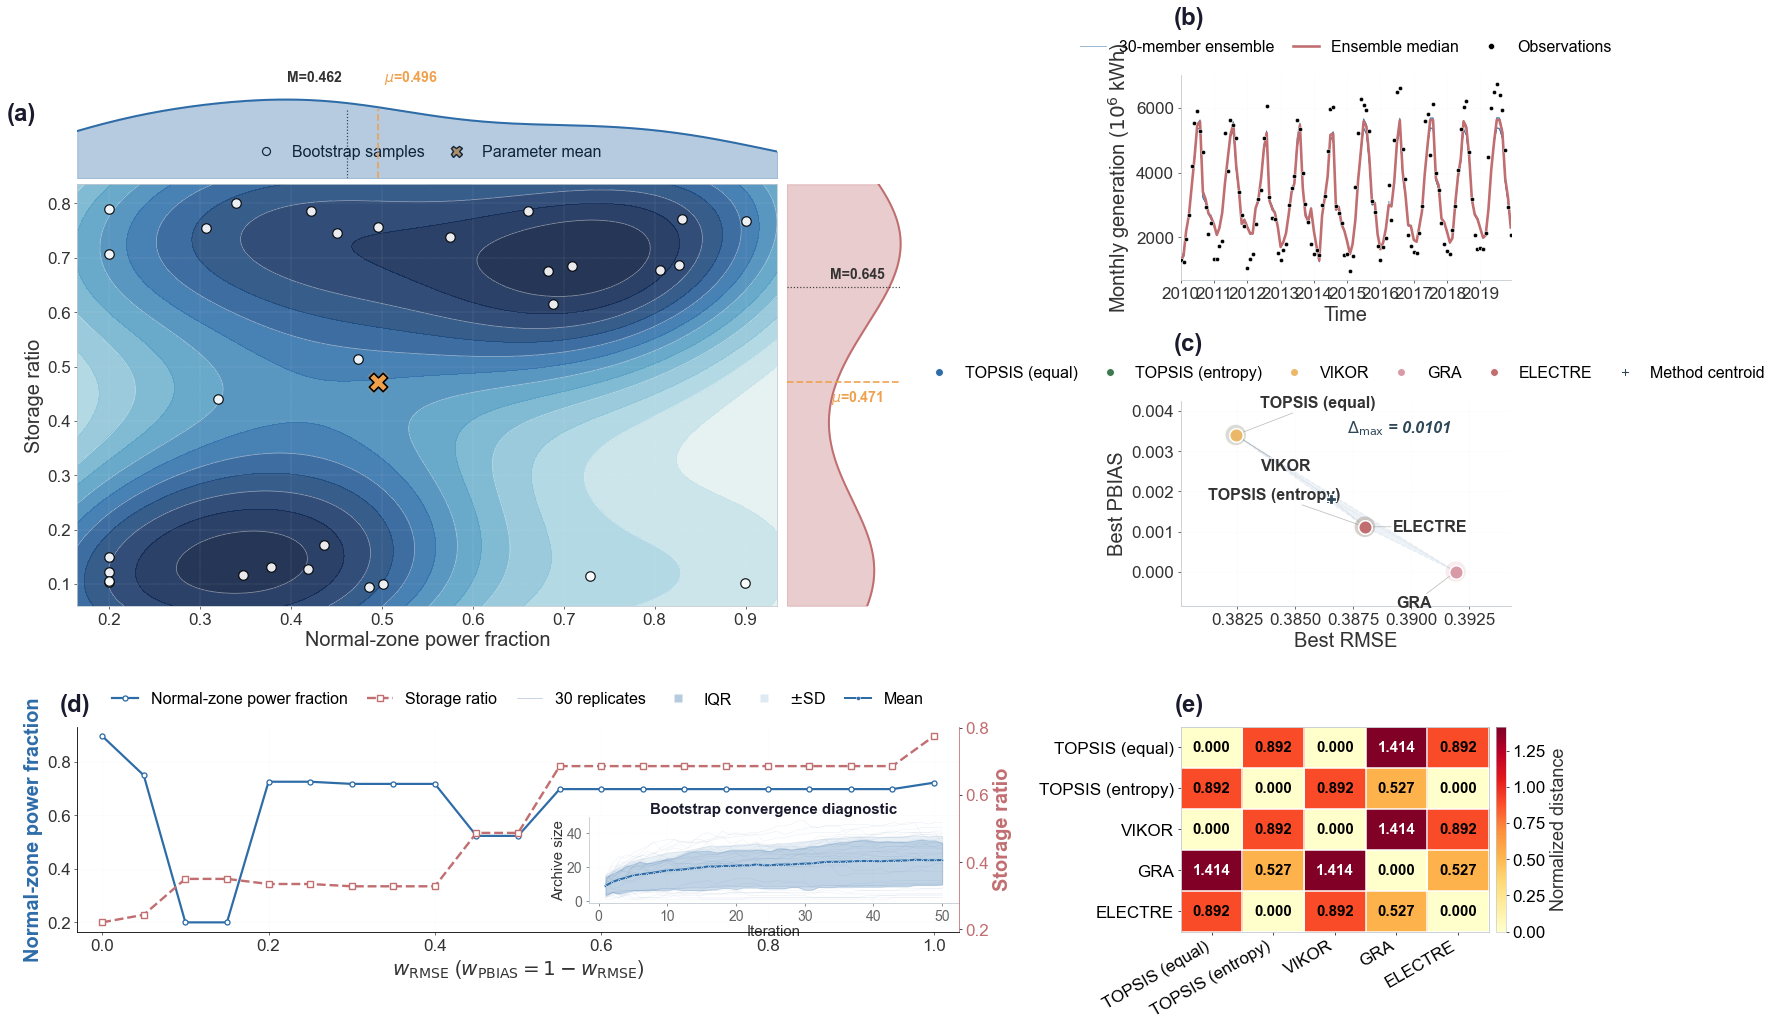

Saved: D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular\Figure_B_enSolution_Uncertainty_and_Robustness.png


In [7]:
# -*- coding: utf-8 -*-
"""
Figure B: Solution uncertainty and robustness (renumbered, 5 panels)
    (a) Joint parameter distribution (KDE contours + marginal distributions)
    (b) Spaghetti plot (2010 onward)
    (c) Cross-comparison of multiple decision-making methods
    (d) Weight scan + inset Bootstrap convergence diagnostic
    (e) Consistency (agreement) matrix of decision-making methods
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde


# ============================================================
# ========== Fonts ===========================================
# ============================================================
FS_LABEL    = 20
FS_TICK     = 17
FS_LEGEND   = 16
FS_PANEL    = 24
FS_CB_LABEL = 18
FS_CB_TICK  = 16
FS_ANNO     = 16
FS_INSET_LABEL = 15
FS_INSET_TICK  = 14
FS_MARGINAL    = 14

rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False
rcParams['font.size'] = FS_LABEL
rcParams['axes.linewidth'] = 0.8
rcParams['xtick.major.width'] = 0.7
rcParams['ytick.major.width'] = 0.7
rcParams['xtick.major.size'] = 3
rcParams['ytick.major.size'] = 3


# ============================================================
# ========== Layout parameters (edit here) ===================
# ============================================================
LAYOUT = {
    # ---- Outer margins of the figure ----
    'margin_left':   0.050,     # left margin
    'margin_right':  0.045,     # right margin
    'margin_bottom': 0.065,     # bottom margin
    'margin_top':    0.085,     # top margin

    # ---- Gaps between panels ----
    'h_gap':         0.14,      # horizontal gap (between adjacent columns)
    'v_gap':         0.120,     # vertical gap (between adjacent rows)

    # ---- Figure size ----
    'fig_w':         22,        # figure width (inches)
    'fig_h':         14,        # figure height (inches)
    'n_row':         3,
    'n_col':         3,
}


DATA_PATH = r"D:\Python code\boshilunwen\电站模拟\results_kaidu_20261012_140128"
OUTPUT_PATH = r"D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular"
ACTUAL_PATH = r"D:\Python code\boshilunwen\电站模拟\dianliang.xlsx"
os.makedirs(OUTPUT_PATH, exist_ok=True)

UD = os.path.join(DATA_PATH, 'uncertainty')
DECISION_DIR = os.path.join(UD, 'decision')
BOOT_DIR = os.path.join(UD, 'bootstrap')
BAND_DIR = os.path.join(UD, 'prediction_band')

P1 = 'normal_zone_power_fraction'
P2 = 'storage_ratio'
P1_EN = 'Normal-zone power fraction'
P2_EN = 'Storage ratio'


# ============================================================
# ========== Colormaps =======================================
# ============================================================
CMAP_MAIN = LinearSegmentedColormap.from_list(
    'modern_main', ['#0a1a3a', '#1b3a6b', '#2e6ca8',
                    '#5fa8c9', '#a7d4e0', '#f0f7f4'], N=256)
CMAP_JOINT = LinearSegmentedColormap.from_list(
    'joint', ['#f0f7f4', '#a7d4e0', '#5fa8c9',
              '#2e6ca8', '#1b3a6b', '#0a1a3a'], N=256)

COL_P1 = '#2e6ca8'
COL_P2 = '#c16e71'
COL_HL = '#f0a04b'
COL_NEUTRAL = '#2f4858'
COL_GRID = '#e8ecf0'

METHOD_COLORS = {
    'TOPSIS_Equal':       '#2e6ca8',
    'TOPSIS_Entropy':     '#3d7a4f',
    'VIKOR':              '#eab867',
    'GRA':                '#d99aa8',
    'Simplified_ELECTRE': '#c16e71',
}
METHOD_LABELS_EN = {
    'TOPSIS_Equal':       'TOPSIS (equal)',
    'TOPSIS_Entropy':     'TOPSIS (entropy)',
    'VIKOR':              'VIKOR',
    'GRA':                'GRA',
    'Simplified_ELECTRE': 'ELECTRE',
}


# ============================================================
# ========== Utility functions ================================
# ============================================================
def add_panel_label(ax, label, x=-0.02, y=1.05):
    ax.text(x, y, label, transform=ax.transAxes,
            fontsize=FS_PANEL, fontweight='bold',
            va='bottom', ha='left', clip_on=False,
            color='#1a1a2e')


def style_axis(ax):
    ax.grid(True, linestyle=':', linewidth=0.5,
            color=COL_GRID, alpha=0.7, zorder=0)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_color('#c0c8d0')
        ax.spines[spine].set_linewidth(0.8)
    ax.tick_params(axis='both', labelsize=FS_TICK,
                   colors='#333333')
    ax.set_facecolor('none')
    ax.patch.set_visible(False)


def glow_point(ax, x, y, color, s_main=180, s_glow=420,
               edge='white', zorder_main=8):
    ax.scatter([x], [y], s=s_glow, color=color,
               alpha=0.18, edgecolor='none',
               zorder=zorder_main - 1)
    ax.scatter([x], [y], s=s_main, color=color,
               edgecolor=edge, linewidth=1.4,
               zorder=zorder_main)


def legend_top(ax, handles, labels, ncol=None,
               anchor=(0.5, 1.02), loc='lower center'):
    if ncol is None:
        ncol = len(handles)
    leg = ax.legend(handles, labels,
                    loc=loc,
                    bbox_to_anchor=anchor,
                    ncol=ncol,
                    fontsize=FS_LEGEND,
                    frameon=False,
                    columnspacing=1.2,
                    handlelength=1.6,
                    borderpad=0.5)


# ============================================================
# ========== (a) Joint parameter distribution ================
# ============================================================
def plot_joint_distribution(fig, pos, boot_df, panel='(a)'):
    x0, y0, w, h = pos

    margin_ratio = 0.20
    pad = 0.006

    main_w = w * (1 - margin_ratio - pad)
    main_h = h * (1 - margin_ratio - pad)

    main_pos  = [x0, y0, main_w, main_h]
    top_pos   = [x0, y0 + main_h + pad,
                 main_w, h * margin_ratio]
    right_pos = [x0 + main_w + pad, y0,
                 w * margin_ratio, main_h]

    ax_main  = fig.add_axes(main_pos)
    ax_top   = fig.add_axes(top_pos)
    ax_right = fig.add_axes(right_pos)

    if boot_df.empty:
        for a in [ax_main, ax_top, ax_right]:
            a.set_facecolor('none')
            a.patch.set_visible(False)
        add_panel_label(ax_main, panel, x=-0.10, y=1.10)
        return

    cx = 'Best_' + P1
    cy = 'Best_' + P2
    if cx not in boot_df.columns or cy not in boot_df.columns:
        for a in [ax_main, ax_top, ax_right]:
            a.set_facecolor('none')
            a.patch.set_visible(False)
        add_panel_label(ax_main, panel, x=-0.10, y=1.10)
        return

    x = boot_df[cx].values.astype(float)
    y = boot_df[cy].values.astype(float)
    m_ = np.isfinite(x) & np.isfinite(y)
    x = x[m_]; y = y[m_]

    pad_x = 0.05 * (x.max() - x.min() + 1e-9)
    pad_y = 0.05 * (y.max() - y.min() + 1e-9)
    xmin, xmax = max(x.min() - pad_x, 0.0), min(x.max() + pad_x, 1.0)
    ymin, ymax = max(y.min() - pad_y, 0.0), min(y.max() + pad_y, 1.0)

    try:
        xx, yy = np.meshgrid(
            np.linspace(xmin, xmax, 120),
            np.linspace(ymin, ymax, 120))
        positions = np.vstack([xx.ravel(), yy.ravel()])
        kernel = gaussian_kde(np.vstack([x, y]))
        zz = kernel(positions).reshape(xx.shape)

        levels = np.linspace(zz.min(), zz.max(), 14)
        ax_main.contourf(xx, yy, zz, levels=levels,
                         cmap=CMAP_JOINT, alpha=0.90,
                         zorder=1)
        ax_main.contour(xx, yy, zz, levels=levels[::2],
                        colors='white', linewidths=0.7,
                        alpha=0.6, zorder=2)
    except Exception as e:
        print('[WARN] KDE 2D failed: %s' % e)

    ax_main.scatter(x, y, s=90,
                    color='white',
                    edgecolor='black',
                    linewidth=1.2,
                    alpha=0.9, zorder=6)

    mx, my = np.mean(x), np.mean(y)
    ax_main.scatter(mx, my, s=520, marker='X',
                    color=COL_HL, alpha=0.28,
                    edgecolor='none', zorder=8)
    ax_main.scatter(mx, my, s=340, marker='X',
                    color=COL_HL,
                    edgecolor='black', linewidth=1.6,
                    zorder=10)

    ax_main.set_xlim(xmin, xmax)
    ax_main.set_ylim(ymin, ymax)
    ax_main.set_xlabel(P1_EN, fontsize=FS_LABEL,
                       color='#333333', labelpad=3)
    ax_main.set_ylabel(P2_EN, fontsize=FS_LABEL,
                       color='#333333', labelpad=3)

    ax_main.grid(True, linestyle=':', linewidth=0.4,
                 color='white', alpha=0.5, zorder=3)
    for spine in ax_main.spines.values():
        spine.set_color('#c0c8d0')
        spine.set_linewidth(0.8)
    ax_main.tick_params(axis='both', labelsize=FS_TICK,
                        colors='#333333')
    ax_main.set_facecolor('none')
    ax_main.patch.set_visible(False)

    handles_main = [
        Line2D([], [], marker='o', linestyle='None',
               markersize=8, markerfacecolor='white',
               markeredgecolor='black', markeredgewidth=1.2),
        Line2D([], [], marker='X', linestyle='None',
               markersize=11, markerfacecolor=COL_HL,
               markeredgecolor='black', markeredgewidth=1.4),
    ]
    labels_main = ['Bootstrap samples', 'Parameter mean']
    legend_top(ax_main, handles_main, labels_main, ncol=2)

    # ---------- Top margin: KDE of P1 ----------
    try:
        kde_x = gaussian_kde(x)
        xg = np.linspace(xmin, xmax, 200)
        yg = kde_x(xg)
        yg = yg / yg.max()

        ax_top.fill_between(xg, 0, yg,
                            color=COL_P1, alpha=0.35, zorder=3)
        ax_top.plot(xg, yg, color=COL_P1,
                    linewidth=2.0, zorder=4)
    except Exception:
        pass

    ax_top.axvline(mx, color=COL_HL,
                   ymin=0, ymax=0.65,
                   linewidth=1.8, linestyle='--',
                   alpha=0.9, zorder=5)
    med_x = np.median(x)
    ax_top.axvline(med_x, color='black',
                   ymin=0, ymax=0.65,
                   linewidth=1.2, linestyle=':',
                   alpha=0.7, zorder=5)

    ax_top.set_xlim(xmin, xmax)
    ax_top.set_ylim(0, 1.35)
    ax_top.set_yticks([])
    ax_top.set_xticks([])
    for spine in ax_top.spines.values():
        spine.set_visible(False)
    ax_top.patch.set_visible(False)

    # Annotate mean and median separately (no background box)
    if mx < med_x:
        mu_ha, mu_dx = 'right', -6
        med_ha, med_dx = 'left', 6
    else:
        mu_ha, mu_dx = 'left', 6
        med_ha, med_dx = 'right', -6

    def to_norm_x(xv):
        return (xv - xmin) / (xmax - xmin + 1e-9)

    ax_top.annotate(
        r'$\mu$=%.3f' % mx,
        xy=(to_norm_x(mx), 0.95),
        xycoords='axes fraction',
        xytext=(mu_dx, 0),
        textcoords='offset points',
        fontsize=FS_MARGINAL,
        color=COL_HL, fontweight='bold',
        va='center', ha=mu_ha)

    ax_top.annotate(
        'M=%.3f' % med_x,
        xy=(to_norm_x(med_x), 0.95),
        xycoords='axes fraction',
        xytext=(med_dx, 0),
        textcoords='offset points',
        fontsize=FS_MARGINAL,
        color='#333333', fontweight='bold',
        va='center', ha=med_ha)

    # ---------- Right margin: KDE of P2 ----------
    try:
        kde_y = gaussian_kde(y)
        yg2 = np.linspace(ymin, ymax, 200)
        xg2 = kde_y(yg2)
        xg2 = xg2 / xg2.max()

        ax_right.fill_betweenx(yg2, 0, xg2,
                               color=COL_P2, alpha=0.35, zorder=3)
        ax_right.plot(xg2, yg2, color=COL_P2,
                      linewidth=2.0, zorder=4)
    except Exception:
        pass

    ax_right.axhline(my, color=COL_HL,
                     xmin=0, xmax=0.65,
                     linewidth=1.8, linestyle='--',
                     alpha=0.9, zorder=5)
    med_y = np.median(y)
    ax_right.axhline(med_y, color='black',
                     xmin=0, xmax=0.65,
                     linewidth=1.2, linestyle=':',
                     alpha=0.7, zorder=5)

    ax_right.set_ylim(ymin, ymax)
    ax_right.set_xlim(0, 1.55)
    ax_right.set_xticks([])
    ax_right.set_yticks([])
    for spine in ax_right.spines.values():
        spine.set_visible(False)
    ax_right.patch.set_visible(False)

    if my < med_y:
        mu_va, mu_dy = 'top', -6
        med_va, med_dy = 'bottom', 6
    else:
        mu_va, mu_dy = 'bottom', 6
        med_va, med_dy = 'top', -6

    def to_norm_y(yv):
        return (yv - ymin) / (ymax - ymin + 1e-9)

    ax_right.annotate(
        r'$\mu$=%.3f' % my,
        xy=(0.40, to_norm_y(my)),
        xycoords='axes fraction',
        xytext=(0, mu_dy),
        textcoords='offset points',
        fontsize=FS_MARGINAL,
        color=COL_HL, fontweight='bold',
        va=mu_va, ha='center')

    ax_right.annotate(
        'M=%.3f' % med_y,
        xy=(0.40, to_norm_y(med_y)),
        xycoords='axes fraction',
        xytext=(0, med_dy),
        textcoords='offset points',
        fontsize=FS_MARGINAL,
        color='#333333', fontweight='bold',
        va=med_va, ha='center')

    add_panel_label(ax_main, panel, x=-0.10, y=1.14)


# ============================================================
# ========== (b) Spaghetti plot ==============================
# ============================================================
def plot_spaghetti_recent(ax, panel='(b)'):
    ens_path = os.path.join(BAND_DIR,
                            'ensemble_monthly_generation.csv')
    if not os.path.exists(ens_path):
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    ens = pd.read_csv(ens_path, index_col=0,
                      parse_dates=True)
    if ens.empty:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    ens = ens.loc['2010-01-01':]
    if ens.empty:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    for c in ens.columns:
        ax.plot(ens.index, ens[c],
                color=COL_P1, linewidth=0.6,
                alpha=0.28, zorder=2)

    med = ens.median(axis=1)
    ax.plot(med.index, med.values,
            color=COL_P2, linewidth=2.6, zorder=5)

    obs_plotted = False
    try:
        adf = pd.read_excel(ACTUAL_PATH)
        adf['time'] = pd.to_datetime(adf['time'])
        adf['time'] = (adf['time'].dt.to_period('M')
                       .dt.to_timestamp())
        adf['power'] = pd.to_numeric(adf['power'],
                                     errors='coerce')
        adf = adf.dropna(subset=['time', 'power'])
        adf = adf.set_index('time').sort_index()
        adf = adf.loc['2010-01-01':]

        common = ens.index.intersection(adf.index)
        if len(common) > 0:
            ax.scatter(common,
                       adf.loc[common, 'power'].values,
                       s=18, color='black',
                       edgecolor='white', linewidth=0.5,
                       zorder=8)
            obs_plotted = True
    except Exception as e:
        print('[WARN] actual load failed: %s' % e)

    handles = [
        Line2D([], [], color=COL_P1, linewidth=0.8, alpha=0.6),
        Line2D([], [], color=COL_P2, linewidth=2.6),
    ]
    labels = ['30-member ensemble', 'Ensemble median']
    if obs_plotted:
        handles.append(Line2D([], [], marker='o',
                              linestyle='None',
                              markersize=6,
                              markerfacecolor='black',
                              markeredgecolor='white',
                              markeredgewidth=0.5))
        labels.append('Observations')
    legend_top(ax, handles, labels, ncol=len(handles))

    ax.set_xlabel('Time', fontsize=FS_LABEL, color='#333333')
    ax.set_ylabel(r'Monthly generation ($10^{6}$ kWh)',
                  fontsize=FS_LABEL, color='#333333')
    add_panel_label(ax, panel,y=1.22)
    style_axis(ax)
    ax.margins(x=0)


# ============================================================
# ========== (c) Multi-method comparison =====================
# ============================================================
def plot_method_comparison(ax, method_df, panel='(c)'):
    if method_df.empty:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    points = []
    for _, r in method_df.iterrows():
        m = r['Method']
        points.append({
            'x': float(r['Obj_RMSE']),
            'y': float(r['Obj_PBIAS']),
            'label': METHOD_LABELS_EN.get(m, m),
            'color': METHOD_COLORS.get(m, '#888888'),
        })
    if not points:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    xs = np.array([p['x'] for p in points])
    ys = np.array([p['y'] for p in points])

    try:
        from scipy.spatial import ConvexHull
        if len(points) >= 3:
            pts = np.column_stack([xs, ys])
            hull = ConvexHull(pts)
            hull_pts = pts[hull.vertices]
            hull_pts = np.vstack([hull_pts, hull_pts[0]])
            ax.fill(hull_pts[:, 0], hull_pts[:, 1],
                    color=COL_P1, alpha=0.08,
                    zorder=1, edgecolor=COL_P1,
                    linewidth=1.2, linestyle='--')
    except Exception:
        pass

    cx, cy = np.mean(xs), np.mean(ys)
    for p in points:
        ax.plot([cx, p['x']], [cy, p['y']],
                color='#b0b8c0', linewidth=0.6,
                alpha=0.55, zorder=2, linestyle=':')

    ax.scatter(cx, cy, s=120, marker='P',
               color=COL_NEUTRAL, edgecolor='white',
               linewidth=1.2, zorder=4)

    dirs = [(24, 24), (-24, 24), (24, -24),
            (-24, -24), (28, 0), (-28, 0)]
    for i, p in enumerate(points):
        glow_point(ax, p['x'], p['y'], p['color'],
                   s_main=180, s_glow=420, zorder_main=8)
        dx, dy = dirs[i % len(dirs)]
        ha = 'left' if dx > 0 else ('right' if dx < 0 else 'center')
        va = 'bottom' if dy > 0 else ('top' if dy < 0 else 'center')
        ax.annotate(p['label'],
                    xy=(p['x'], p['y']),
                    xycoords='data',
                    xytext=(dx, dy),
                    textcoords='offset points',
                    fontsize=FS_ANNO, color='#333333',
                    fontweight='bold',
                    ha=ha, va=va,
                    arrowprops=dict(arrowstyle='-',
                                    color='#999999',
                                    linewidth=0.7,
                                    alpha=0.7,
                                    shrinkA=0, shrinkB=6))

    # Maximum inter-method difference (no bbox, bottom-right corner)
    spread = np.sqrt((xs.max() - xs.min()) ** 2 +
                     (ys.max() - ys.min()) ** 2)
    ax.text(0.82, 0.82,
            r'$\Delta_{\max}$ = %.4f' % spread,
            transform=ax.transAxes,
            fontsize=FS_ANNO,
            color=COL_NEUTRAL,
            fontweight='bold',
            va='bottom', ha='right',
            style='italic')

    handles = []
    labels = []
    for _, r in method_df.iterrows():
        m = r['Method']
        handles.append(
            Line2D([], [], marker='o', linestyle='None',
                   markersize=8,
                   markerfacecolor=METHOD_COLORS.get(m, '#888'),
                   markeredgecolor='white',
                   markeredgewidth=1.0))
        labels.append(METHOD_LABELS_EN.get(m, m))
    handles.append(Line2D([], [], marker='P', linestyle='None',
                          markersize=8,
                          markerfacecolor=COL_NEUTRAL,
                          markeredgecolor='white',
                          markeredgewidth=1.0))
    labels.append('Method centroid')
    legend_top(ax, handles, labels, ncol=len(handles))

    add_panel_label(ax, panel,y=1.22)
    ax.set_xlabel('Best RMSE', fontsize=FS_LABEL, color='#333333')
    ax.set_ylabel('Best PBIAS', fontsize=FS_LABEL, color='#333333')
    style_axis(ax)
    ax.margins(x=0.25, y=0.25)


# ============================================================
# ========== (d) Weight scan + inset Bootstrap diagnostic ====
# ============================================================
def plot_weight_scan_with_inset(ax, scan_df, panel='(d)'):
    if scan_df.empty:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    df = scan_df.sort_values('w_RMSE')
    w = df['w_RMSE'].values
    y1 = df[P1].values
    y2 = df[P2].values

    ax.plot(w, y1, color=COL_P1, linewidth=2.2,
            marker='o', markersize=5,
            markerfacecolor='white',
            markeredgecolor=COL_P1,
            markeredgewidth=1.3, zorder=6)

    ax.set_xlabel(
        r'$w_{\mathrm{RMSE}}$ ($w_{\mathrm{PBIAS}} = 1 - w_{\mathrm{RMSE}}$)',
        fontsize=FS_LABEL, color='#333333')
    ax.set_ylabel(P1_EN, fontsize=FS_LABEL,
                  color=COL_P1, fontweight='bold')
    ax.tick_params(axis='y', labelcolor=COL_P1)
    ax.patch.set_visible(False)

    ax2 = ax.twinx()
    ax2.plot(w, y2, color=COL_P2, linewidth=2.4,
             linestyle='--',
             marker='s', markersize=6,
             markerfacecolor='white',
             markeredgecolor=COL_P2,
             markeredgewidth=1.4, zorder=10)

    ax2.set_ylabel(P2_EN, fontsize=FS_LABEL,
                   color=COL_P2, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor=COL_P2)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_color(COL_P2)
    ax2.patch.set_visible(False)

    inset_handles = []
    inset_labels = []
    try:
        hist_list = []
        for i in range(1, 31):
            p = os.path.join(BOOT_DIR,
                             'replicate_%03d' % i,
                             'convergence.csv')
            if os.path.exists(p):
                df_ = pd.read_csv(p)
                if 'Iteration' in df_.columns and \
                   'Archive_Size' in df_.columns:
                    hist_list.append(
                        df_[['Iteration', 'Archive_Size']])

        if hist_list:
            iter_axis = hist_list[0]['Iteration'].values
            ax_data = np.array(
                [d['Archive_Size'].values for d in hist_list])
            mean_a = ax_data.mean(axis=0)
            std_a = ax_data.std(axis=0)
            q25 = np.percentile(ax_data, 25, axis=0)
            q75 = np.percentile(ax_data, 75, axis=0)

            axins = ax.inset_axes([0.58, 0.14, 0.42, 0.42],
                                   facecolor='#ffffff')
            axins.patch.set_alpha(0.95)

            for i in range(ax_data.shape[0]):
                axins.plot(iter_axis, ax_data[i],
                           color='#8fa8c8',
                           linewidth=0.4,
                           alpha=0.22, zorder=1)

            axins.fill_between(iter_axis, q25, q75,
                               color=COL_P1, alpha=0.22, zorder=2)
            axins.fill_between(iter_axis,
                               mean_a - std_a,
                               mean_a + std_a,
                               color=COL_P1, alpha=0.10, zorder=1)

            axins.plot(iter_axis, mean_a,
                       color=COL_P1, linewidth=2.0,
                       marker='o', markersize=2.2,
                       markerfacecolor=COL_P1,
                       markeredgecolor='white',
                       markeredgewidth=0.5, zorder=5)

            axins.set_xlabel('Iteration',
                             fontsize=FS_INSET_LABEL,
                             color='#333333', labelpad=1)
            axins.set_ylabel('Archive size',
                             fontsize=FS_INSET_LABEL,
                             color='#333333', labelpad=1)
            axins.tick_params(axis='both',
                              labelsize=FS_INSET_TICK,
                              colors='#666666')
            for sp_ in ['top', 'right']:
                axins.spines[sp_].set_visible(False)
            for sp_ in ['bottom', 'left']:
                axins.spines[sp_].set_color('#c0c8d0')
                axins.spines[sp_].set_linewidth(0.8)
            axins.grid(True, linestyle=':',
                       linewidth=0.35,
                       color='#e8ecf0', alpha=0.7)
            axins.set_axisbelow(True)
            axins.set_title('Bootstrap convergence diagnostic',
                            fontsize=FS_INSET_LABEL,
                            pad=3, color='#1a1a2e',
                            fontweight='bold')

            inset_handles = [
                Line2D([], [], color='#8fa8c8',
                       linewidth=0.6, alpha=0.8),
                Line2D([], [], color=COL_P1, linewidth=0,
                       marker='s', markersize=8,
                       markerfacecolor=COL_P1, alpha=0.35,
                       markeredgecolor='none'),
                Line2D([], [], color=COL_P1, linewidth=0,
                       marker='s', markersize=8,
                       markerfacecolor=COL_P1, alpha=0.15,
                       markeredgecolor='none'),
                Line2D([], [], color=COL_P1, linewidth=2.0,
                       marker='o', markersize=4,
                       markerfacecolor=COL_P1,
                       markeredgecolor='white',
                       markeredgewidth=0.5),
            ]
            inset_labels = ['30 replicates', 'IQR', r'$\pm$SD', 'Mean']
    except Exception as e:
        print('[WARN] inset convergence failed: %s' % e)

    main_handles = [
        Line2D([], [], color=COL_P1, linewidth=2.2,
               marker='o', markersize=5,
               markerfacecolor='white',
               markeredgecolor=COL_P1, markeredgewidth=1.3),
        Line2D([], [], color=COL_P2, linewidth=2.4,
               linestyle='--',
               marker='s', markersize=6,
               markerfacecolor='white',
               markeredgecolor=COL_P2, markeredgewidth=1.4),
    ]
    main_labels = [P1_EN, P2_EN]

    all_handles = main_handles + inset_handles
    all_labels = main_labels + inset_labels

    legend_top(ax, all_handles, all_labels,
               ncol=len(all_handles))

    add_panel_label(ax, panel)
    style_axis(ax)
    ax.margins(x=0.03)


# ============================================================
# ========== (e) Decision-method agreement matrix ============
# ============================================================
def plot_agreement_matrix(ax, method_df, panel='(e)'):
    if method_df.empty:
        add_panel_label(ax, panel)
        style_axis(ax)
        return

    methods = method_df['Method'].values
    labels = [METHOD_LABELS_EN.get(m, m) for m in methods]
    x = method_df['Obj_RMSE'].values.astype(float)
    y = method_df['Obj_PBIAS'].values.astype(float)

    den_x = x.max() - x.min()
    den_y = y.max() - y.min()
    den_x = den_x if den_x > 1e-12 else 1.0
    den_y = den_y if den_y > 1e-12 else 1.0
    x_n = (x - x.min()) / den_x
    y_n = (y - y.min()) / den_y

    n = len(methods)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = np.sqrt((x_n[i] - x_n[j]) ** 2 +
                              (y_n[i] - y_n[j]) ** 2)

    im = ax.imshow(D, cmap='YlOrRd',
                   vmin=0,
                   vmax=D.max() if D.max() > 0 else 1,
                   aspect='auto',
                   interpolation='nearest')

    cb = plt.colorbar(im, ax=ax, pad=0.02, fraction=0.046)
    cb.set_label('Normalized distance', fontsize=FS_CB_LABEL,
                 color='#333333')
    cb.ax.tick_params(labelsize=FS_CB_TICK)
    cb.outline.set_edgecolor('#c0c8d0')
    cb.outline.set_linewidth(0.6)

    dmax = D.max() if D.max() > 0 else 1.0
    for i in range(n):
        for j in range(n):
            v = D[i, j]
            color = 'white' if v > 0.65 * dmax else 'black'
            ax.text(j, i, '%.3f' % v,
                    ha='center', va='center',
                    fontsize=FS_CB_TICK - 1,
                    color=color, fontweight='bold')

    ax.set_xticks(np.arange(n))
    ax.set_xticklabels(labels, fontsize=FS_CB_TICK,
                       rotation=30, ha='right')
    ax.set_yticks(np.arange(n))
    ax.set_yticklabels(labels, fontsize=FS_CB_TICK)

    ax.set_xticks(np.arange(n + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(n + 1) - 0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=1.5)
    ax.tick_params(which='minor', length=0)
    ax.grid(which='major', visible=False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#c0c8d0')
        spine.set_linewidth(0.8)

    ax.set_facecolor('none')

    add_panel_label(ax, panel)


# ============================================================
# ========== Main ============================================
# ============================================================
def main():
    print('Loading data...')
    scan_p = os.path.join(DECISION_DIR,
                          'topsis_preference_scan.csv')
    method_p = os.path.join(DECISION_DIR,
                            'decision_method_comparison.csv')
    bdf_p = os.path.join(BOOT_DIR, 'bootstrap_hv.csv')

    scan_df = pd.read_csv(scan_p) \
        if os.path.exists(scan_p) else pd.DataFrame()
    method_df = pd.read_csv(method_p) \
        if os.path.exists(method_p) else pd.DataFrame()
    boot_df = pd.read_csv(bdf_p) \
        if os.path.exists(bdf_p) else pd.DataFrame()

    print('  scan: %d, method: %d, boot: %d'
          % (len(scan_df), len(method_df), len(boot_df)))

    fig = plt.figure(figsize=(LAYOUT['fig_w'], LAYOUT['fig_h']),
                     facecolor='white')
    fig.patch.set_facecolor('white')

    ml = LAYOUT['margin_left']
    mr = LAYOUT['margin_right']
    mb = LAYOUT['margin_bottom']
    mt = LAYOUT['margin_top']
    hg = LAYOUT['h_gap']
    vg = LAYOUT['v_gap']
    n_row = LAYOUT['n_row']
    n_col = LAYOUT['n_col']

    total_w = 1.0 - ml - mr
    total_h = 1.0 - mb - mt
    cell_w = (total_w - (n_col - 1) * hg) / n_col
    cell_h = (total_h - (n_row - 1) * vg) / n_row

    # ---------- Panel positions ----------
    # (a) top-left, 2x2
    a_x = ml
    a_y = 1.0 - mt - 2 * cell_h - vg
    a_w = 2 * cell_w + hg
    a_h = 2 * cell_h + vg

    # (b) top-right (row 0, col 2)
    b_x = ml + 2 * (cell_w + hg)
    b_y = 1.0 - mt - cell_h
    b_w = cell_w
    b_h = cell_h

    # (c) middle-right (row 1, col 2)
    c_x = ml + 2 * (cell_w + hg)
    c_y = 1.0 - mt - 2 * cell_h - vg
    c_w = cell_w
    c_h = cell_h

    # (d) bottom spanning 2 columns (row 2, cols 0-1)
    d_x = ml
    d_y = mb
    d_w = 2 * cell_w + hg
    d_h = cell_h

    # (e) bottom-right (row 2, col 2)
    e_x = ml + 2 * (cell_w + hg)
    e_y = mb
    e_w = cell_w
    e_h = cell_h

    plot_joint_distribution(fig,
                            [a_x, a_y, a_w, a_h],
                            boot_df, panel='(a)')

    ax_b = fig.add_axes([b_x, b_y, b_w, b_h])
    plot_spaghetti_recent(ax_b, panel='(b)')

    ax_c = fig.add_axes([c_x, c_y, c_w, c_h])
    plot_method_comparison(ax_c, method_df, panel='(c)')

    ax_d = fig.add_axes([d_x, d_y, d_w, d_h])
    plot_weight_scan_with_inset(ax_d, scan_df, panel='(d)')

    ax_e = fig.add_axes([e_x, e_y, e_w, e_h])
    plot_agreement_matrix(ax_e, method_df, panel='(e)')

    for ax0 in fig.axes:
        ax0.tick_params(axis='both', labelsize=FS_TICK)

    save_path = os.path.join(
        OUTPUT_PATH,
        'Figure_B_enSolution_Uncertainty_and_Robustness.png')
    plt.savefig(save_path, dpi=600,
                bbox_inches='tight', facecolor='white',
                edgecolor='none')
    plt.show()
    print('Saved: %s' % save_path)


if __name__ == '__main__':
    main()

Loading data...
  band: 480, metrics: 1, oat: 7
  Layout coordinates:
    a: [0.045, 0.613, 0.565, 0.257]
    b: [0.665, 0.613, 0.304, 0.257]
    c: [0.045, 0.328, 0.417, 0.245]
    d: [0.552, 0.328, 0.417, 0.245]
    e: [0.045, 0.055, 0.539, 0.233]
    f: [0.639, 0.055, 0.331, 0.233]


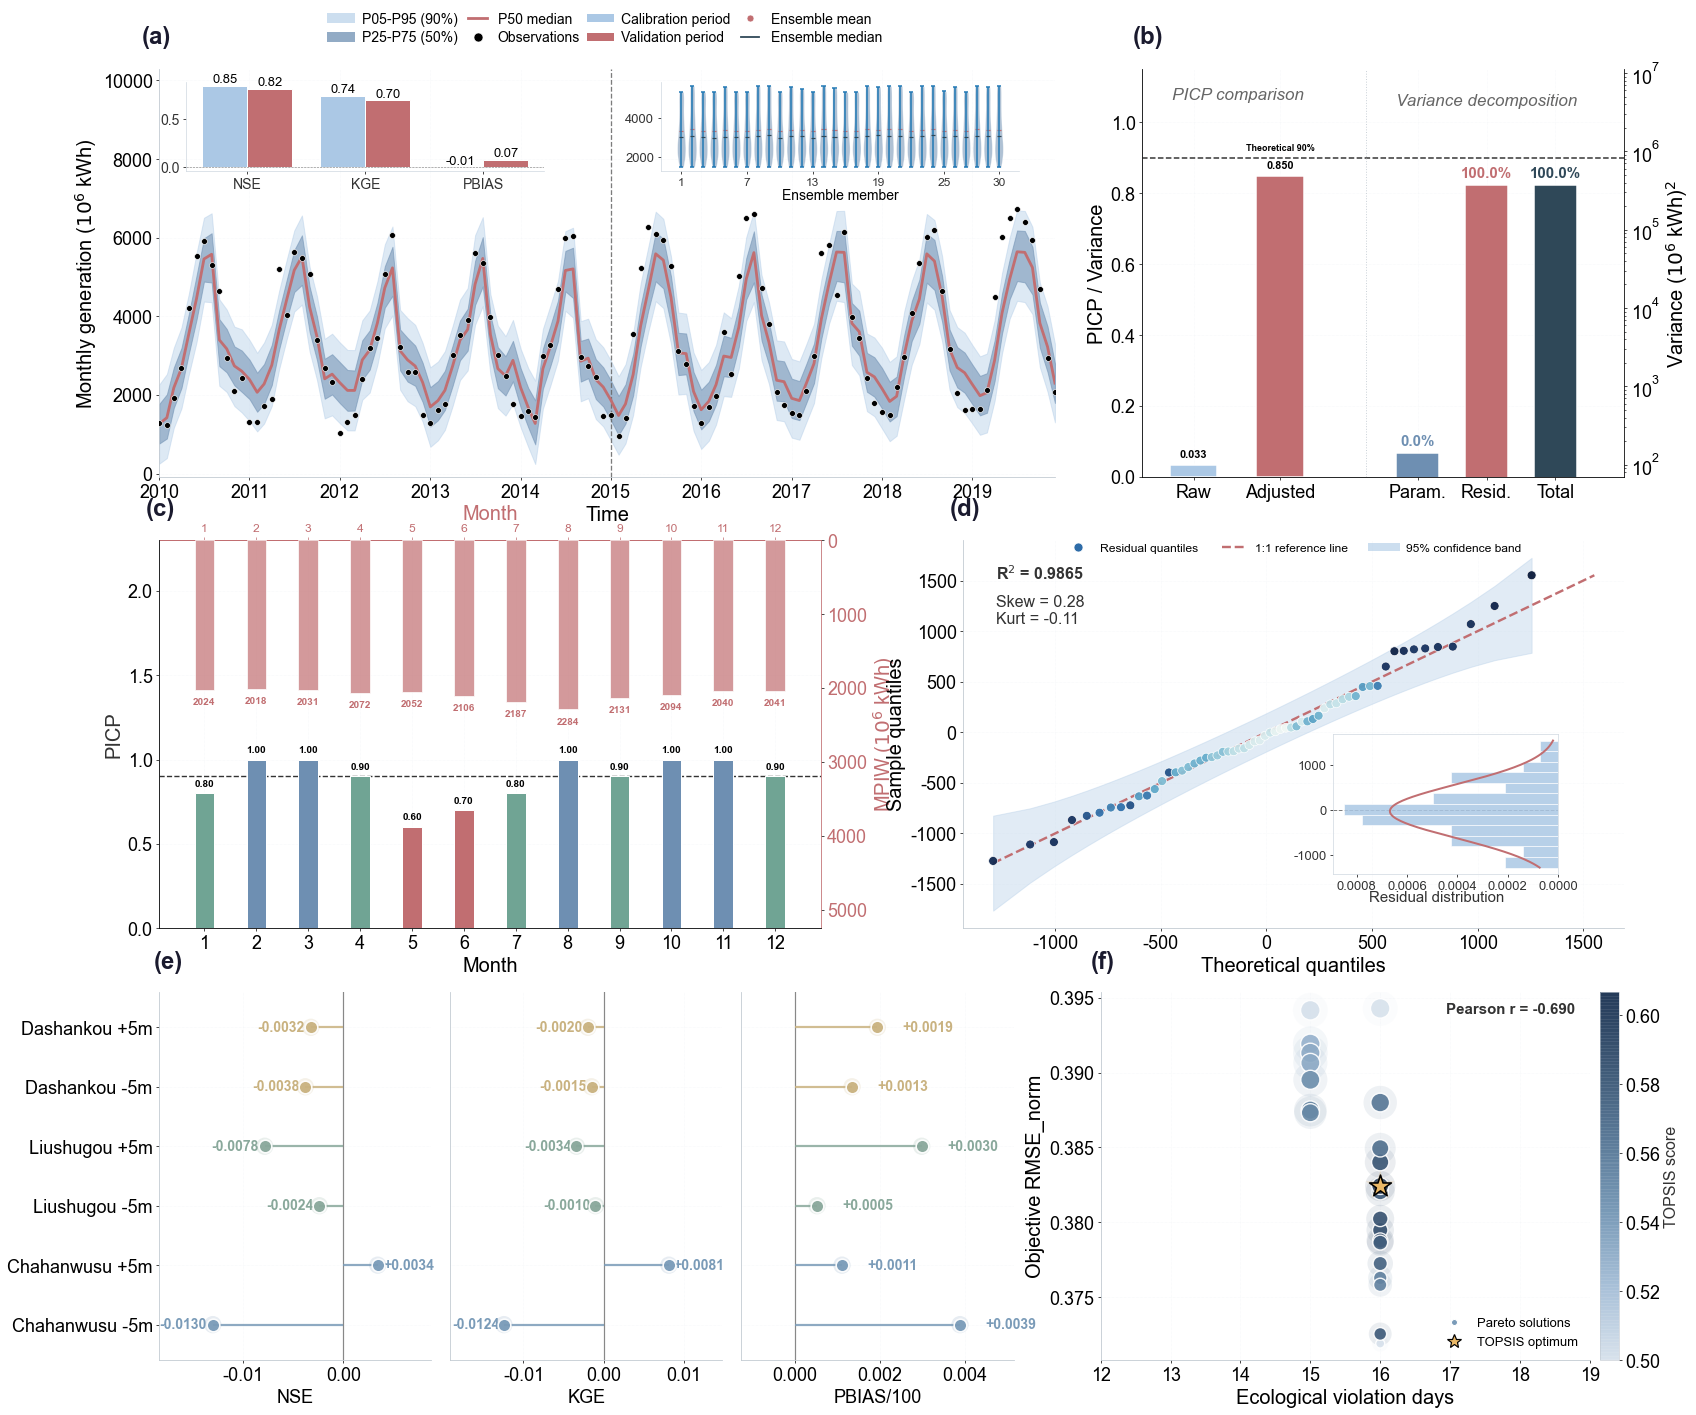

Saved: D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular\Figure_CD_enPrediction_Uncertainty_and_Engineering_Robustness.png


In [8]:
# -*- coding: utf-8 -*-
"""
Figure CD: Prediction uncertainty and engineering robustness (3-row combined layout)
    (a) Monthly generation prediction uncertainty band + inset calibration/validation + inset ensemble violin
    (b) PICP comparison + variance decomposition
    (c) Monthly PICP upward + MPIW downward (dual y-axes + top secondary x-axis)
    (d) Residual QQ density main panel + inset horizontal histogram
    (e) Dead water level OAT: three side-by-side lollipop plots (ΔNSE / ΔKGE / ΔPBIAS)
    (f) Ecology-generation two-dimensional scatter plot (bubble + density coloring)
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import gaussian_kde


# ============================================================
# ========== Fonts ===========================================
# ============================================================
FONT_SIZE = 22
LABEL_SIZE = 20
TICK_SIZE = 18
LEGEND_SIZE = 18
SUBLABEL_SIZE = 24

FS_IN_LABEL = 16
FS_IN_TICK  = 14

rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False
rcParams['font.size'] = FONT_SIZE


# ============================================================
# ========== Layout parameters (3-row layout) ================
# ============================================================
LAYOUT = {
    # Figure margins
    'margin_left':   0.045,
    'margin_right':  0.030,
    'margin_bottom': 0.055,
    'margin_top':    0.130,

    # Column gaps (within each row)
    'h_gap_row1':    0.055,   # row 1: gap between a and b
    'h_gap_row2':    0.090,   # row 2: gap between c and d
    'h_gap_row3':    0.055,   # row 3: gap between e and f

    # Row gaps (between rows)
    'v_gap_12':      0.04,    # between row 1 and row 2
    'v_gap_23':      0.04,    # between row 2 and row 3

    # Row width ratios (within each row)
    'row1_a_ratio':  0.65,
    'row2_c_ratio':  0.50,
    'row3_e_ratio':  0.62,

    # Row height ratios
    'row1_h_ratio':  1.05,
    'row2_h_ratio':  1.00,
    'row3_h_ratio':  0.95,

    # Inner gap for the three subpanels in panel (e)
    'h_gap_e_inner': 0.0120,

    'fig_w':         22,
    'fig_h':         22,
}


DATA_PATH = r"D:\Python code\boshilunwen\电站模拟\results_kaidu_20261012_140128"
OUTPUT_PATH = r"D:\Python code\boshilunwen\电站模拟\paper_figures_tables_irregular"
ACTUAL_PATH = r"D:\Python code\boshilunwen\电站模拟\dianliang.xlsx"
os.makedirs(OUTPUT_PATH, exist_ok=True)

BAND_DIR = os.path.join(DATA_PATH, 'uncertainty', 'prediction_band')
DEAD_DIR = os.path.join(DATA_PATH, 'uncertainty', 'dead_level')


# ============================================================
# ========== Colormaps =======================================
# ============================================================
CMAP_DENSITY = LinearSegmentedColormap.from_list(
    'density', ['#0a1a3a', '#1b3a6b', '#2e6ca8',
                '#5fa8c9', '#a7d4e0', '#f0f7f4'], N=256)

CMAP_SCATTER = LinearSegmentedColormap.from_list(
    'scatter',
    ['#d8e2ec', '#a8c0d8', '#7a9bb8',
     '#5a7a98', '#3d5876', '#243a58'],
    N=256)

COL_CH = '#7a9bb8'
COL_LS = '#89a89b'
COL_DS = '#c9b280'

RES_LABELS = {
    'Chahanwusu-5': 'Chahanwusu -5m',
    'Chahanwusu+5': 'Chahanwusu +5m',
    'Liushugou-5': 'Liushugou -5m',
    'Liushugou+5': 'Liushugou +5m',
    'Dashankou-5': 'Dashankou -5m',
    'Dashankou+5': 'Dashankou +5m',
}

SCEN_ORDER = [
    'Chahanwusu-5', 'Chahanwusu+5',
    'Liushugou-5', 'Liushugou+5',
    'Dashankou-5', 'Dashankou+5',
]


# ============================================================
# ========== Utility functions ===============================
# ============================================================
def add_panel_label(ax, label, x=-0.02, y=1.05):
    ax.text(x, y, label, transform=ax.transAxes,
            fontsize=SUBLABEL_SIZE, fontweight='bold',
            va='bottom', ha='left', clip_on=False,
            color='#1a1a2e')


def style_axis(ax, show_y=True):
    ax.grid(True, linestyle=':', linewidth=0.5,
            color='#e8ecf0', alpha=0.7, zorder=0)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_color('#c0c8d0')
    ax.spines['left'].set_color('#c0c8d0')
    ax.tick_params(axis='both', labelsize=TICK_SIZE)
    if not show_y:
        ax.tick_params(axis='y', left=False, labelleft=False)


def _res_color(scen):
    for r, c in [('Chahanwusu', COL_CH),
                 ('Liushugou', COL_LS),
                 ('Dashankou', COL_DS)]:
        if str(scen).startswith(r):
            return c
    return '#999999'


def load_actual(path):
    df = pd.read_excel(path)
    df['time'] = pd.to_datetime(df['time'])
    df['time'] = df['time'].dt.to_period('M').dt.to_timestamp()
    df['power'] = pd.to_numeric(df['power'], errors='coerce')
    df = df.dropna(subset=['time', 'power']).sort_values('time')
    df.set_index('time', inplace=True)
    return df['power']


def compute_metrics(sim, obs):
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)
    m = np.isfinite(sim) & np.isfinite(obs)
    sim = sim[m]; obs = obs[m]
    if len(sim) < 2:
        return np.nan, np.nan, np.nan
    nse = 1 - np.sum((sim - obs) ** 2) / \
        max(np.sum((obs - obs.mean()) ** 2), 1e-12)
    r = (np.corrcoef(sim, obs)[0, 1]
         if np.std(sim) > 1e-12 and np.std(obs) > 1e-12 else np.nan)
    alpha = np.std(sim) / max(np.std(obs), 1e-12)
    beta = np.mean(sim) / max(abs(np.mean(obs)), 1e-12)
    kge = (1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 +
                       (beta - 1) ** 2)
           if np.isfinite(r) else np.nan)
    pb = 100 * np.sum(obs - sim) / max(abs(np.sum(obs)), 1e-12)
    return nse, kge, pb


def draw_lollipop(ax, y_positions, values, colors,
                  line_width=2.2, dot_size=160,
                  glow_size=300,
                  value_fmt='%+.4f',
                  value_fontsize=None,
                  value_offset=0.0006):
    if value_fontsize is None:
        value_fontsize = TICK_SIZE - 4

    for y, v, c in zip(y_positions, values, colors):
        ax.hlines(y, 0, v, color=c,
                  linewidth=line_width,
                  alpha=0.85, zorder=3)

    for y, v, c in zip(y_positions, values, colors):
        ax.scatter([v], [y], s=glow_size, color=c,
                   alpha=0.18, edgecolor='none', zorder=4)
        ax.scatter([v], [y], s=dot_size, color=c,
                   alpha=0.95, edgecolor='white',
                   linewidth=1.6, zorder=5)

    ax.axvline(0, color='#888888',
               linewidth=1.2, zorder=2)

    for y, v, c in zip(y_positions, values, colors):
        off = value_offset if v >= 0 else -value_offset
        ax.text(v + off, y, value_fmt % v,
                ha='left' if v >= 0 else 'right',
                va='center',
                fontsize=value_fontsize,
                fontweight='bold', color=c)


# ============================================================
# ========== (a) Prediction band + insets + merged legend ====
# ============================================================
def plot_band_with_insets(ax, band, actual):
    common = band.index.intersection(actual.index)
    obs = actual.loc[common].values
    b = band.loc[common]

    ax.fill_between(b.index, b['P05'], b['P95'],
                    color='#abc8e5', alpha=0.40)
    ax.fill_between(b.index, b['P25'], b['P75'],
                    color='#6e8fb2', alpha=0.55)
    ax.plot(b.index, b['P50'], color='#c16e71',
            linewidth=2.8, zorder=5)
    ax.scatter(common, obs, s=34, color='black',
               edgecolor='white', linewidth=0.6, zorder=6)

    ax.axvline(pd.Timestamp('2015-01-01'),
               color='#666666', linewidth=1.3,
               linestyle='--', alpha=0.85)

    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + (y1 - y0) * 0.45)

    ax.set_xlabel('Time', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'Monthly generation ($10^6$ kWh)',
                  fontsize=LABEL_SIZE)
    style_axis(ax)
    ax.margins(x=0)

    # ---- Inset 1: calibration vs validation period ----
    try:
        cal = band.loc['2010-01':'2014-12'].index.intersection(
            actual.loc['2010-01':'2014-12'].index)
        val = band.loc['2015-01':'2019-12'].index.intersection(
            actual.loc['2015-01':'2019-12'].index)
        if len(cal) >= 2 and len(val) >= 2:
            nc, kc, pc = compute_metrics(
                band.loc[cal, 'P50'].values,
                actual.loc[cal].values)
            nv, kv, pv = compute_metrics(
                band.loc[val, 'P50'].values,
                actual.loc[val].values)

            axins1 = ax.inset_axes([0.03, 0.75, 0.40, 0.22])
            axins1.patch.set_visible(False)
            axins1.set_facecolor('none')

            x = np.arange(3)
            w = 0.38
            cv_ = [nc, kc, pc / 100.0]
            vv_ = [nv, kv, pv / 100.0]

            axins1.bar(x - w / 2, cv_, w,
                       color='#abc8e5',
                       edgecolor='white', linewidth=1.0)
            axins1.bar(x + w / 2, vv_, w,
                       color='#c16e71',
                       edgecolor='white', linewidth=1.0)

            for i, (a_, b_) in enumerate(zip(cv_, vv_)):
                axins1.text(i - w / 2, a_, '%.2f' % a_,
                            ha='center', va='bottom',
                            fontsize=FS_IN_TICK - 1)
                axins1.text(i + w / 2, b_, '%.2f' % b_,
                            ha='center', va='bottom',
                            fontsize=FS_IN_TICK - 1)

            axins1.axhline(0, color='gray',
                           linewidth=0.6, linestyle='--')

            axins1.set_xticks(x)
            axins1.set_xticklabels(['NSE', 'KGE', 'PBIAS'],
                                    fontsize=FS_IN_TICK)
            axins1.tick_params(axis='both',
                                labelsize=FS_IN_TICK,
                                labelcolor='#333333')
            for sp_ in ['top', 'right']:
                axins1.spines[sp_].set_visible(False)
            for sp_ in ['bottom', 'left']:
                axins1.spines[sp_].set_color('#d0d8e0')
                axins1.spines[sp_].set_linewidth(0.7)
    except Exception as e:
        print('[WARN] inset1 failed: %s' % e)

    # ---- Inset 2: ensemble violin ----
    try:
        ens_p = os.path.join(BAND_DIR,
                             'ensemble_monthly_generation.csv')
        if os.path.exists(ens_p):
            ens = pd.read_csv(ens_p, index_col=0,
                              parse_dates=True)
            val_months = band.loc['2015-01':'2019-12']
            if len(val_months) < 6:
                val_months = band
            val_ens = ens.loc[
                ens.index.intersection(val_months.index)]
            data = [val_ens[c].values
                    for c in val_ens.columns]
            if len(data) > 1:
                axins2 = ax.inset_axes([0.56, 0.75, 0.40, 0.22])
                axins2.patch.set_visible(False)
                axins2.set_facecolor('none')

                n_members = len(data)
                positions = np.arange(1, n_members + 1)

                parts = axins2.violinplot(data,
                                           positions=positions,
                                           showmeans=True,
                                           showmedians=True,
                                           widths=0.75)
                for pc in parts['bodies']:
                    pc.set_facecolor('#6e8fb2')
                    pc.set_alpha(0.55)
                    pc.set_edgecolor('white')
                    pc.set_linewidth(0.6)
                parts['cmeans'].set_color('#c16e71')
                parts['cmeans'].set_linewidth(1.2)
                parts['cmedians'].set_color('#2f4858')
                parts['cmedians'].set_linewidth(1.2)

                if n_members > 10:
                    step = max(1, n_members // 5)
                    tick_pos = list(range(1, n_members + 1, step))
                    if n_members not in tick_pos:
                        tick_pos.append(n_members)
                else:
                    tick_pos = list(range(1, n_members + 1))

                axins2.set_xticks(tick_pos)
                axins2.set_xticklabels(
                    ['%d' % p for p in tick_pos],
                    fontsize=FS_IN_TICK - 2)
                axins2.set_xlabel('Ensemble member',
                                   fontsize=FS_IN_TICK,
                                   labelpad=1)
                axins2.tick_params(axis='y',
                                    labelsize=FS_IN_TICK - 1,
                                    labelcolor='#333333')
                axins2.tick_params(axis='x',
                                    labelsize=FS_IN_TICK - 2,
                                    labelcolor='#333333')

                for sp_ in ['top', 'right']:
                    axins2.spines[sp_].set_visible(False)
                for sp_ in ['bottom', 'left']:
                    axins2.spines[sp_].set_color('#d0d8e0')
                    axins2.spines[sp_].set_linewidth(0.7)
    except Exception as e:
        print('[WARN] inset2 failed: %s' % e)

    # ---- Merged legend ----
    all_handles = [
        Line2D([], [], color='#abc8e5', linewidth=10,
               alpha=0.6, label='P05-P95 (90%)'),
        Line2D([], [], color='#6e8fb2', linewidth=10,
               alpha=0.75, label='P25-P75 (50%)'),
        Line2D([], [], color='#c16e71', linewidth=2.8,
               label='P50 median'),
        Line2D([], [], marker='o', linestyle='None',
               markersize=9, markerfacecolor='black',
               markeredgecolor='white', markeredgewidth=0.6,
               label='Observations'),
        Line2D([], [], color='#abc8e5', linewidth=8,
               label='Calibration period'),
        Line2D([], [], color='#c16e71', linewidth=8,
               label='Validation period'),
        Line2D([], [], marker='o', linestyle='None',
               markersize=7, markerfacecolor='#c16e71',
               markeredgecolor='white', markeredgewidth=0.7,
               label='Ensemble mean'),
        Line2D([], [], color='#2f4858', linewidth=1.8,
               label='Ensemble median'),
    ]

    ax.legend(handles=all_handles,
              fontsize=LEGEND_SIZE - 4,
              frameon=False,
              loc='lower center',
              bbox_to_anchor=(0.5, 1.03),
              ncol=4,
              columnspacing=0.8,
              handlelength=1.3,
              borderpad=0.4,
              labelspacing=0.3)

    add_panel_label(ax, '(a)')


# ============================================================
# ========== (b) PICP comparison + variance decomposition ====
# ============================================================
def plot_uncertainty_decomp(ax, band, metrics):
    if metrics.empty:
        add_panel_label(ax, '(b)')
        return

    m = metrics.iloc[0]
    picp_raw = float(m.get('PICP_90_raw', np.nan))
    picp_adj = float(m.get('PICP_90', np.nan))

    if 'P05_raw' in band.columns and 'P05' in band.columns:
        w_raw = (band['P95_raw'] - band['P05_raw']).mean()
        w_adj = (band['P95'] - band['P05']).mean()
        var_param = (w_raw / 3.29) ** 2
        var_total = (w_adj / 3.29) ** 2
        var_resid = max(var_total - var_param, 0.0)
    else:
        sigma = float(m.get('Sigma_resid', 0.0))
        var_param = 0.0
        var_resid = sigma ** 2
        var_total = var_resid

    x_picp = np.array([0, 1])
    bars1 = ax.bar(x_picp, [picp_raw, picp_adj],
                   width=0.55,
                   color=['#abc8e5', '#c16e71'],
                   edgecolor='white', linewidth=1.5,
                   zorder=3)
    for b, v in zip(bars1, [picp_raw, picp_adj]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015,
                '%.3f' % v, ha='center', va='bottom',
                fontsize=TICK_SIZE - 7, fontweight='bold')

    ax.axhline(0.90, color='black', linewidth=1.5,
               linestyle='--', alpha=0.8, zorder=2)
    ax.text(1.4, 0.915, 'Theoretical 90%',
            fontsize=TICK_SIZE - 9, color='black',
            ha='right', va='bottom', fontweight='bold')

    ax.set_xlim(-0.6, 5.0)
    ax.set_ylim(0, 1.15)
    ax.set_xticks([0, 1, 2.6, 3.4, 4.2])
    ax.set_xticklabels(['Raw', 'Adjusted', 'Param.', 'Resid.', 'Total'],
                       fontsize=TICK_SIZE - 8)
    ax.set_ylabel('PICP / Variance', fontsize=LABEL_SIZE)

    ax.text(-0.25, 1.10, 'PICP comparison',
            fontsize=TICK_SIZE - 1, color='#666666',
            va='top', ha='left', style='italic')
    ax.axvline(2.0, color='#c0c8d0',
               linewidth=1.0, linestyle=':', alpha=0.8)

    x_var = np.array([2.6, 3.4, 4.2])
    vals = [var_param, var_resid, var_total]
    colors = ['#6e8fb2', '#c16e71', '#2f4858']

    ax2 = ax.twinx()
    ax2.bar(x_var, vals, width=0.5,
            color=colors, edgecolor='white',
            linewidth=1.5, zorder=3)
    ax2.set_yscale('log')
    ax2.set_ylabel(r'Variance ($10^6$ kWh)$^2$',
                   fontsize=LABEL_SIZE)

    total = max(var_total, 1e-9)
    for xv, v, c in zip(x_var, vals, colors):
        pct = v / total * 100
        ax2.text(xv, v * 1.15,
                 '%.1f%%' % pct,
                 ha='center', va='bottom',
                 fontsize=TICK_SIZE - 3,
                 fontweight='bold', color=c)

    y_lo = var_param * 0.5 if var_param > 0 else 1
    ax2.set_ylim(y_lo, var_total * 30)
    ax2.spines['top'].set_visible(False)
    ax2.tick_params(axis='y', labelsize=TICK_SIZE - 6)

    ax2.text(3.4, ax2.get_ylim()[1] * 0.5, 'Variance decomposition',
             fontsize=TICK_SIZE - 1, color='#666666',
             va='top', ha='center', style='italic')

    add_panel_label(ax, '(b)')
    style_axis(ax)


# ============================================================
# ========== (c) PICP upward + MPIW downward + top secondary x-axis
# ============================================================
def plot_monthly_updown(ax, band, actual):
    common = band.index.intersection(actual.index)
    if len(common) < 12:
        add_panel_label(ax, '(c)')
        return

    b = band.loc[common]
    obs = actual.loc[common].values
    months = common.month

    picp = np.zeros(12)
    mpiw = np.zeros(12)
    for mi in range(1, 13):
        mask = months == mi
        if mask.any():
            inside = (obs[mask] >= b['P05'].values[mask]) & \
                     (obs[mask] <= b['P95'].values[mask])
            picp[mi - 1] = np.mean(inside)
            mpiw[mi - 1] = (b['P95'].values[mask] -
                            b['P05'].values[mask]).mean()

    x = np.arange(1, 13)
    w = 0.38

    colors = ['#c16e71' if p < 0.80 else
              ('#6e8fb2' if p > 0.95 else '#70a494')
              for p in picp]
    bars = ax.bar(x, picp, w,
                  color=colors, edgecolor='white',
                  linewidth=1.0, zorder=3)
    for b_, v in zip(bars, picp):
        ax.text(b_.get_x() + b_.get_width() / 2,
                v + 0.03, '%.2f' % v,
                ha='center', va='bottom',
                fontsize=TICK_SIZE - 8,
                fontweight='bold')

    ax.axhline(0.90, color='black', linewidth=1.4,
               linestyle='--', alpha=0.8, zorder=2)
    ax.set_ylim(0, 2.30)
    ax.set_ylabel('PICP', fontsize=LABEL_SIZE,
                  color='#333333')
    ax.set_xticks(x)
    ax.set_xticklabels(['%d' % m for m in range(1, 13)],
                       fontsize=TICK_SIZE - 6)
    ax.set_xlabel('Month', fontsize=LABEL_SIZE)

    ax2 = ax.twinx()
    bars2 = ax2.bar(x, mpiw, w,
                    color='#c16e71', alpha=0.70,
                    edgecolor='white',
                    linewidth=1.0, zorder=3)

    mpiw_max = mpiw.max() * 1.15 if mpiw.max() > 0 else 1
    ax2.set_ylim(mpiw_max * 2.0, 0)

    for b_, v in zip(bars2, mpiw):
        ax2.text(b_.get_x() + b_.get_width() / 2,
                 v * 1.05, '%.0f' % v,
                 ha='center', va='top',
                 fontsize=TICK_SIZE - 8,
                 fontweight='bold', color='#c16e71')

    ax2.set_ylabel(r'MPIW ($10^6$ kWh)',
                   fontsize=LABEL_SIZE, color='#c16e71')
    ax2.tick_params(axis='y', labelcolor='#c16e71',
                    labelsize=TICK_SIZE - 4)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_color('#c16e71')

    try:
        secax = ax.secondary_xaxis('top')
        secax.set_xticks(x)
        secax.set_xticklabels(['%d' % m for m in range(1, 13)],
                              fontsize=TICK_SIZE - 6)
        secax.set_xlabel('Month', fontsize=LABEL_SIZE)
        secax.tick_params(axis='x',
                          labelsize=TICK_SIZE - 6,
                          colors='#c16e71')
        secax.spines['top'].set_color('#c16e71')
        secax.spines['top'].set_linewidth(1.0)
        secax.xaxis.label.set_color('#c16e71')
    except Exception as e:
        print('[WARN] secondary_xaxis failed: %s' % e)

    add_panel_label(ax, '(c)')
    style_axis(ax)
    ax.margins(x=0.06)


# ============================================================
# ========== (d) QQ density main panel + inset horizontal histogram
# ============================================================
def plot_residual_diagnostic(ax, band, actual):
    cal = band.loc['2010-01':'2014-12'].index.intersection(
        actual.loc['2010-01':'2014-12'].index)
    if len(cal) < 10:
        add_panel_label(ax, '(d)')
        return
    resid = actual.loc[cal].values - band.loc[cal, 'P50'].values
    resid = resid[np.isfinite(resid)]
    if len(resid) < 10:
        add_panel_label(ax, '(d)')
        return

    mu = float(np.mean(resid))
    sigma = float(np.std(resid, ddof=1))

    resid_s = np.sort(resid)
    n = len(resid_s)
    q = np.arange(1, n + 1) / (n + 1)
    theo = mu + sigma * stats.norm.ppf(q)

    pdf_q = stats.norm.pdf(stats.norm.ppf(q))
    pdf_q = np.where(pdf_q < 1e-6, 1e-6, pdf_q)
    se = sigma * np.sqrt(q * (1 - q) / n) / pdf_q
    upper = theo + 1.96 * se
    lower = theo - 1.96 * se

    ax.fill_between(theo, lower, upper,
                    color='#abc8e5', alpha=0.35, zorder=2)

    try:
        xy = np.vstack([theo, resid_s])
        z = gaussian_kde(xy)(xy)
        z = z / z.max()
        ax.scatter(theo, resid_s, c=z,
                   cmap=CMAP_DENSITY,
                   s=80, edgecolor='white',
                   linewidth=0.7, alpha=0.95,
                   zorder=5)
    except Exception:
        ax.scatter(theo, resid_s, s=80,
                   color='#2e6ca8',
                   edgecolor='white',
                   linewidth=0.7, alpha=0.9,
                   zorder=5)

    lo = min(theo.min(), resid_s.min())
    hi = max(theo.max(), resid_s.max())
    ax.plot([lo, hi], [lo, hi], color='#c16e71',
            linewidth=2.4, linestyle='--', zorder=3)

    r2 = np.corrcoef(theo, resid_s)[0, 1] ** 2
    ax.text(0.05, 0.94, 'R$^2$ = %.4f' % r2,
            transform=ax.transAxes,
            fontsize=TICK_SIZE - 2, color='#333333',
            va='top', ha='left', fontweight='bold')

    try:
        skew_v = float(stats.skew(resid))
        kurt_v = float(stats.kurtosis(resid))
        ax.text(0.05, 0.86,
                'Skew = %.2f\nKurt = %.2f' % (skew_v, kurt_v),
                transform=ax.transAxes,
                fontsize=TICK_SIZE - 2, color='#333333',
                va='top', ha='left')
    except Exception:
        pass

    ax.set_xlabel('Theoretical quantiles', fontsize=LABEL_SIZE)
    ax.set_ylabel('Sample quantiles', fontsize=LABEL_SIZE)

    handles = [
        Line2D([], [], marker='o', linestyle='None',
               markersize=9, markerfacecolor='#2e6ca8',
               markeredgecolor='white',
               markeredgewidth=0.7, label='Residual quantiles'),
        Line2D([], [], color='#c16e71', linewidth=2.4,
               linestyle='--', label='1:1 reference line'),
        Line2D([], [], color='#abc8e5', linewidth=8,
               alpha=0.6, label='95% confidence band'),
    ]
    ax.legend(handles=handles,
              fontsize=LEGEND_SIZE - 6,
              frameon=False,
              loc='upper center',
              bbox_to_anchor=(0.5, 1.02),
              ncol=3)

    try:
        axins = ax.inset_axes([0.560, 0.14, 0.34, 0.36])
        axins.patch.set_visible(False)
        axins.set_facecolor('none')

        axins.hist(resid, bins=12,
                   orientation='horizontal',
                   color='#abc8e5',
                   edgecolor='white',
                   linewidth=0.7,
                   alpha=0.85,
                   density=True,
                   zorder=3)

        xg = np.linspace(resid.min(), resid.max(), 200)
        pdf = (1 / (sigma * np.sqrt(2 * np.pi))) * \
            np.exp(-0.5 * ((xg - mu) / sigma) ** 2)
        axins.plot(pdf, xg, color='#c16e71',
                   linewidth=2.0, zorder=4)

        axins.axhline(0, color='#666666',
                      linewidth=1.0, linestyle='--',
                      alpha=0.85)

        axins.invert_xaxis()

        axins.tick_params(axis='both',
                          labelsize=FS_IN_TICK - 1,
                          labelcolor='#333333')
        for sp_ in axins.spines.values():
            sp_.set_edgecolor('#d0d8e0')
            sp_.set_linewidth(0.7)

        axins.text(0.46, -0.12, 'Residual distribution',
                   transform=axins.transAxes,
                   fontsize=FS_IN_LABEL - 1,
                   color='#333333',
                   va='top', ha='center')
    except Exception as e:
        print('[WARN] inset hist failed: %s' % e)

    add_panel_label(ax, '(d)')
    style_axis(ax)
    ax.margins(x=0.05, y=0.05)


# ============================================================
# ========== (e) Dead water level OAT: three side-by-side lollipop plots
# ============================================================
def plot_dead_three_panels(fig, pos_e, oat_df):
    x0, y0, w, h = pos_e
    hg = LAYOUT['h_gap_e_inner']

    panel_w = (w - 2 * hg) / 3.0

    pos_1 = [x0, y0, panel_w, h]
    pos_2 = [x0 + panel_w + hg, y0, panel_w, h]
    pos_3 = [x0 + 2 * (panel_w + hg), y0, panel_w, h]

    ax1 = fig.add_axes(pos_1)
    ax2 = fig.add_axes(pos_2)
    ax3 = fig.add_axes(pos_3)

    if oat_df.empty:
        for a in [ax1, ax2, ax3]:
            style_axis(a)
        add_panel_label(ax1, '(e)')
        return

    df = oat_df.copy()
    df['__order__'] = df['Scenario'].apply(
        lambda x: SCEN_ORDER.index(x) if x in SCEN_ORDER else 999)
    df = df[df['Scenario'] != 'Base']
    df = df.sort_values('__order__').reset_index(drop=True)

    y = np.arange(len(df))
    labels = df['Scenario'].map(RES_LABELS).values
    colors = df['Scenario'].apply(_res_color).values

    base_row = oat_df[oat_df['Scenario'] == 'Base']
    if base_row.empty:
        base_nse = base_kge = base_pb = 0.0
    else:
        base_nse = float(base_row['Val_NSE'].values[0])
        base_kge = float(base_row['Val_KGE'].values[0])
        base_pb = float(base_row['Val_PBIAS'].values[0])

    delta_nse = df['Val_NSE'].values - base_nse
    delta_kge = df['Val_KGE'].values - base_kge
    delta_pb = (df['Val_PBIAS'].values - base_pb) / 100.0

    ranges = [
        (delta_nse, 'NSE', '%+.4f', 0.0006),
        (delta_kge, 'KGE', '%+.4f', 0.0006),
        (delta_pb, 'PBIAS/100', '%+.4f', 0.0006),
    ]

    axes = [ax1, ax2, ax3]

    for ax, (vals, xlabel, fmt, off) in zip(axes, ranges):
        draw_lollipop(ax, y, vals, colors,
                      line_width=2.2, dot_size=160,
                      glow_size=300,
                      value_fmt=fmt,
                      value_fontsize=TICK_SIZE - 4,
                      value_offset=off)

        xmin, xmax = ax.get_xlim()
        xc = (xmin + xmax) / 2
        xw = (xmax - xmin) * 1.5
        ax.set_xlim(xc - xw / 2, xc + xw / 2)
        ax.set_xlabel(xlabel, fontsize=LABEL_SIZE - 2)

    ax1.set_yticks(y)
    ax1.set_yticklabels(labels, fontsize=TICK_SIZE - 3)
    ax2.set_yticks(y)
    ax2.set_yticklabels([])
    ax3.set_yticks(y)
    ax3.set_yticklabels([])

    for ax in [ax1, ax2, ax3]:
        ax.set_ylim(-0.6, len(df) - 0.4)

    style_axis(ax1, show_y=True)
    style_axis(ax2, show_y=False)
    style_axis(ax3, show_y=False)

    add_panel_label(ax1, '(e)')

    for ax, title in zip(axes, ['', '', '']):
        ax.set_title(title, fontsize=LABEL_SIZE - 3,
                     pad=5, color='#333333', fontweight='bold')


# ============================================================
# ========== (f) Ecology-generation 2D scatter plot ==========
# ============================================================
def plot_eco_tradeoff_2d(ax):
    p = os.path.join(DATA_PATH, 'mopso_pareto_front.csv')
    if not os.path.exists(p):
        add_panel_label(ax, '(f)')
        return
    df = pd.read_csv(p)
    if 'Eco_Violation_days' not in df.columns:
        add_panel_label(ax, '(f)')
        return

    x = df['Eco_Violation_days'].values.astype(float)
    y = df['Objective_RMSE_norm'].values.astype(float)
    z = df['Objective_PBIAS_norm'].values.astype(float)

    F = np.column_stack([y, z])
    fmin, fmax = F.min(axis=0), F.max(axis=0)
    den = np.where(fmax - fmin > 1e-12, fmax - fmin, 1.0)
    Z = (F - fmin) / den
    dp = np.linalg.norm(Z - 0, axis=1)
    dn = np.linalg.norm(Z - 1, axis=1)
    score = dn / (dp + dn + 1e-12)

    z_min, z_max = z.min(), z.max()
    den_z = z_max - z_min if z_max - z_min > 1e-9 else 1.0
    sizes = 80 + 300 * (1 - (z - z_min) / den_z)

    ax.scatter(x, y, s=sizes * 3.2,
               c=score, cmap=CMAP_SCATTER,
               alpha=0.10, edgecolor='none', zorder=2)

    sc = ax.scatter(x, y, s=sizes,
                    c=score, cmap=CMAP_SCATTER,
                    edgecolor='white', linewidth=1.4,
                    alpha=0.92, zorder=4)

    cb = plt.colorbar(sc, ax=ax, pad=0.02, fraction=0.046)
    cb.set_label('TOPSIS score',
                 fontsize=LABEL_SIZE - 4, color='#333333')
    cb.ax.tick_params(labelsize=TICK_SIZE - 4)
    cb.outline.set_edgecolor('#c0c8d0')
    cb.outline.set_linewidth(0.6)

    best = int(np.argmax(score))
    ax.scatter(x[best], y[best],
               s=900, marker='*', color='#eab867',
               alpha=0.25, edgecolor='none', zorder=9)
    ax.scatter(x[best], y[best],
               s=520, marker='*', color='#eab867',
               edgecolor='black', linewidth=1.6,
               zorder=10, label='TOPSIS optimum')

    if len(np.unique(x)) > 1:
        r = np.corrcoef(x, y)[0, 1]
        ax.text(0.97, 0.97,
                'Pearson r = %.3f' % r,
                transform=ax.transAxes,
                fontsize=TICK_SIZE - 3,
                color='#333333',
                va='top', ha='right',
                fontweight='bold')

    ax.set_xlabel('Ecological violation days', fontsize=LABEL_SIZE)
    ax.set_ylabel('Objective RMSE_norm', fontsize=LABEL_SIZE)

    ax.set_xlim(12, 19)
    ax.set_xticks([12, 13, 14, 15, 16, 17, 18, 19])

    handles = [
        Line2D([], [], marker='o', linestyle='None',
               markersize=6, markerfacecolor='#7a9bb8',
               markeredgecolor='white', markeredgewidth=1.0,
               label='Pareto solutions'),
        Line2D([], [], marker='*', linestyle='None',
               markersize=14, markerfacecolor='#eab867',
               markeredgecolor='black', markeredgewidth=1.2,
               label='TOPSIS optimum'),
    ]
    ax.legend(handles=handles,
              fontsize=LEGEND_SIZE - 5,
              frameon=False,
              loc='lower right')

    add_panel_label(ax, '(f)')
    style_axis(ax)


# ============================================================
# ========== Main (3-row layout) =============================
# ============================================================
def main():
    print('Loading data...')
    actual = load_actual(ACTUAL_PATH)

    band_p = os.path.join(BAND_DIR,
                          'prediction_band_quantiles.csv')
    metrics_p = os.path.join(BAND_DIR,
                             'prediction_band_metrics.csv')
    oat_p = os.path.join(DEAD_DIR, 'dead_level_sensitivity_oat.csv')

    if not os.path.exists(band_p):
        raise FileNotFoundError('Not found: ' + band_p)
    band = pd.read_csv(band_p, index_col=0, parse_dates=True)
    metrics = pd.read_csv(metrics_p) \
        if os.path.exists(metrics_p) else pd.DataFrame()
    oat_df = pd.read_csv(oat_p) if os.path.exists(oat_p) else pd.DataFrame()

    print('  band: %d, metrics: %d, oat: %d'
          % (len(band), len(metrics), len(oat_df)))

    fig = plt.figure(figsize=(LAYOUT['fig_w'], LAYOUT['fig_h']),
                     facecolor='white')

    ml = LAYOUT['margin_left']
    mr = LAYOUT['margin_right']
    mb = LAYOUT['margin_bottom']
    mt = LAYOUT['margin_top']

    h1 = LAYOUT['h_gap_row1']
    h2 = LAYOUT['h_gap_row2']
    h3 = LAYOUT['h_gap_row3']

    v12 = LAYOUT['v_gap_12']
    v23 = LAYOUT['v_gap_23']

    r1_a = LAYOUT['row1_a_ratio']
    r2_c = LAYOUT['row2_c_ratio']
    r3_e = LAYOUT['row3_e_ratio']

    h1r = LAYOUT['row1_h_ratio']
    h2r = LAYOUT['row2_h_ratio']
    h3r = LAYOUT['row3_h_ratio']

    total_w = 1.0 - ml - mr
    total_h = 1.0 - mb - mt

    # Row heights (allocate remaining space by ratios)
    h_total = total_h - v12 - v23
    sum_ratio = h1r + h2r + h3r
    row1_h = h_total * h1r / sum_ratio
    row2_h = h_total * h2r / sum_ratio
    row3_h = h_total * h3r / sum_ratio

    # y coordinates
    row1_y = 1.0 - mt - row1_h
    row2_y = row1_y - v12 - row2_h
    row3_y = row2_y - v23 - row3_h

    # Panel positions
    # Row 1: a occupies r1_a, b occupies the remainder
    a_w = (total_w - h1) * r1_a
    b_w = (total_w - h1) * (1 - r1_a)
    a_pos = [ml, row1_y, a_w, row1_h]
    b_pos = [ml + a_w + h1, row1_y, b_w, row1_h]

    # Row 2: c occupies r2_c, d occupies the remainder
    c_w = (total_w - h2) * r2_c
    d_w = (total_w - h2) * (1 - r2_c)
    c_pos = [ml, row2_y, c_w, row2_h]
    d_pos = [ml + c_w + h2, row2_y, d_w, row2_h]

    # Row 3: e occupies r3_e, f occupies the remainder
    e_w = (total_w - h3) * r3_e
    f_w = (total_w - h3) * (1 - r3_e)
    e_pos = [ml, row3_y, e_w, row3_h]
    f_pos = [ml + e_w + h3, row3_y, f_w, row3_h]

    print('  Layout coordinates:')
    print('    a: [%.3f, %.3f, %.3f, %.3f]' % tuple(a_pos))
    print('    b: [%.3f, %.3f, %.3f, %.3f]' % tuple(b_pos))
    print('    c: [%.3f, %.3f, %.3f, %.3f]' % tuple(c_pos))
    print('    d: [%.3f, %.3f, %.3f, %.3f]' % tuple(d_pos))
    print('    e: [%.3f, %.3f, %.3f, %.3f]' % tuple(e_pos))
    print('    f: [%.3f, %.3f, %.3f, %.3f]' % tuple(f_pos))

    # ---- Plot ----
    ax_a = fig.add_axes(a_pos)
    plot_band_with_insets(ax_a, band, actual)

    ax_b = fig.add_axes(b_pos)
    plot_uncertainty_decomp(ax_b, band, metrics)

    ax_c = fig.add_axes(c_pos)
    plot_monthly_updown(ax_c, band, actual)

    ax_d = fig.add_axes(d_pos)
    plot_residual_diagnostic(ax_d, band, actual)

    # Panel (e): three lollipop subpanels within the given position
    plot_dead_three_panels(fig, e_pos, oat_df)

    ax_f = fig.add_axes(f_pos)
    plot_eco_tradeoff_2d(ax_f)

    for ax0 in fig.axes:
        try:
            ax0.tick_params(axis='both', labelsize=TICK_SIZE)
        except Exception:
            pass

    save_path = os.path.join(
        OUTPUT_PATH,
        'Figure_CD_enPrediction_Uncertainty_and_Engineering_Robustness.png')
    plt.savefig(save_path, dpi=600,
                bbox_inches='tight', facecolor='white',
                edgecolor='none')
    plt.show()
    print('Saved: %s' % save_path)


if __name__ == '__main__':
    main()